# Task 3: Player Monthly Spending Prediction (V3 — 10-Fold Leak-Free Bayes-L1 Pipeline)
## CPE342 Machine Learning - Team ML009

Notebook นี้มีโค้ดและลอจิกชุดเดียวกับ `task3/train_task3.py` (เวอร์ชัน V3 ล่าสุด) โดยแบ่งเป็นส่วน ๆ เพื่อความสะดวกในการอ่านและกดรันทดสอบ

### สรุปสถาปัตยกรรมและการปรับปรุงหลัก (Zero Data Leakage, 10-Fold CV)
- เป้าหมายคือการทำนายยอดใช้จ่ายรายเดือนของผู้เล่น `spending_30d` (หน่วยบาท) โดยประเมินผลด้วยค่า **Normalized Mean Absolute Error (NMAE)**:
  $$\text{NMAE} = \frac{1}{1 + \frac{\sum_{i=1}^{N} |y_i - \hat{y}_i|}{\sum_{i=1}^{N} y_i}}$$
- **การปรับปรุงสำคัญ 5 ส่วนเหนือ Baseline เดิม (`0.79535` $\rightarrow$ V3 `0.79625`):**
  1. **Corrected Exact Algebraic Recovery:** แก้ไขบั๊กกรณี `total_transactions == 0` (`max(tot_tx, 1) * avg_tx`), ยกเลิกการถมค่าว่าง `seasonal_spending_pattern` ด้วย median (`5.0` ซึ่งติด bias ฤดู Summer), แยก provenance flags (`has_exact_hist`, `hist_from_prev`) และตัด `avg_transaction_value` ออกจากตัวเติม `historical_spending`
  2. **Calibrated Probabilistic Imputers (Fit เฉพาะในแต่ละ Fold):** สร้างความน่าจะเป็น posterior สำหรับ `segment` (Ensemble LGB+XGB+CAT + Deterministic Support Mask 100%), `vip_status` (6-class masked ตาม `is_premium_member`), `days_since_last_purchase` (3-class + binary `<=20` พร้อมขอบเขตจาก `purchase_frequency`), `games_played` (5-class), `epr`, `tot_tx` และสูตรวิเคราะห์ $P(\text{prev} > 1000 \mid \text{hist})$
  3. **Denoised Multi-Paradigm Stage 1 (Per-Segment Nested Blend):** ผสมโมเดล Exact 32-Cell Empirical-Bayes Marginalizer (`Bayes32_Exact`) ร่วมกับ Denoised LightGBM, XGBoost และ CatBoost
  4. **Whale-Aligned Multi-Paradigm Stage 2 (10-Fold CV, Per-Segment Nested L1 Blend):** ผสม 6 โมเดล ได้แก่ Per-Level VIP Multiplicative Raw-THB L1, Exact Censored Raw-THB Log-Linear L1 (smooth-L1 continuation + L-BFGS-B), Scale-Weighted Huber Log-Linear และ Residual GBDT 3 ตัว (`CatBoost` 2 seeds, `XGBoost`, `LightGBM`) ที่ทำนาย $\log(y / m_{\text{param}})$
  5. **Exact Heteroscedastic & Bayesian-L1 Mixture CDF Marginalization (Nested 10-Fold Ablation E1–E5):** ใช้ Vectorized Bisection แก้สมการ $F_i(y^*) = 0.50$ สำหรับแถวที่ `segment`, `season`, `vip_status` หรือ `dslp` เป็นค่าว่าง พร้อม post-clip ที่ 300,000 บาท

> **หมายเหตุการรัน:** รันแบบเต็ม 10-Fold บน CPU ใช้เวลาประมาณ ~12–15 นาที (ตรวจสอบการติดตั้งไลบรารีจาก `requirements.txt` ก่อนรัน)

## 1. การตั้งค่าสภาพแวดล้อม ค่าคงที่ และฟังก์ชันช่วยคำนวณ
โหลดไลบรารีหลัก ตั้งค่า `SEED = 42`, `N_SPLITS = 10`, `MAX_CAP = 300000.0` และนิยามฟังก์ชันคำนวณ `calculate_nmae` กับ Simplex Optimizers สำหรับ L1 MAE และ Binary LogLoss

In [1]:
import os
import json
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, log_loss, mean_absolute_error, accuracy_score, f1_score
from sklearn.linear_model import LogisticRegression, HuberRegressor

import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostClassifier, CatBoostRegressor

SEED = 42
N_SPLITS = 10
EPS = 1e-6
MAX_CAP = 300000.0
np.random.seed(SEED)


def calculate_nmae(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    y_true = np.asarray(y_true, dtype=np.float64)
    y_pred = np.clip(np.asarray(y_pred, dtype=np.float64), 0.0, None)
    y_sum = np.sum(y_true)
    if y_sum <= 0:
        return 0.0
    return float(1.0 / (1.0 + np.sum(np.abs(y_true - y_pred)) / y_sum))


def optimize_l1_simplex_weights(pred_list, y_true, shrink_reg=2e-3):
    """Robust regularized simplex optimization for raw THB MAE using multi-start Powell + Nelder-Mead."""
    n_m = len(pred_list)
    if n_m == 1:
        return np.array([1.0])
    P = np.column_stack(pred_list)
    scale_y = float(np.mean(y_true)) + 1.0
    u_w = np.ones(n_m) / n_m

    def softmax_w(z):
        z = z - np.max(z)
        e = np.exp(z)
        return e / np.sum(e)

    def loss_z(z):
        w = softmax_w(z)
        mae = float(np.mean(np.abs(y_true - P @ w)))
        pen = shrink_reg * scale_y * float(np.sum((w - u_w) ** 2))
        return mae + pen

    maes = [float(np.mean(np.abs(y_true - P[:, i]))) for i in range(n_m)]
    best_i = int(np.argmin(maes))
    starts = [np.zeros(n_m)]
    z_best = np.full(n_m, -1.0)
    z_best[best_i] = 1.0
    starts.append(z_best)

    best_val = np.inf
    best_w = u_w.copy()
    for z0 in starts:
        res = minimize(loss_z, z0, method="Powell", options={"maxiter": 1500, "ftol": 1e-6})
        if res.fun < best_val:
            best_val = res.fun
            best_w = softmax_w(res.x)
        res2 = minimize(loss_z, res.x, method="Nelder-Mead", options={"maxiter": 1500, "xatol": 1e-4, "fatol": 1e-6})
        if res2.fun < best_val:
            best_val = res2.fun
            best_w = softmax_w(res2.x)

    return best_w


def optimize_logloss_simplex_weights(prob_list, y_true, sample_weight=None):
    """Robust simplex optimization for binary LogLoss."""
    n_m = len(prob_list)
    P = np.column_stack([np.clip(p, 1e-6, 1.0 - 1e-6) for p in prob_list])

    def softmax_w(z):
        z = z - np.max(z)
        e = np.exp(z)
        return e / np.sum(e)

    def loss_z(z):
        w = softmax_w(z)
        p = np.clip(P @ w, 1e-6, 1.0 - 1e-6)
        ll = -(y_true * np.log(p) + (1.0 - y_true) * np.log(1.0 - p))
        if sample_weight is not None:
            return float(np.sum(sample_weight * ll) / np.sum(sample_weight))
        return float(np.mean(ll))

    res = minimize(loss_z, np.zeros(n_m), method="Powell", options={"maxiter": 1000})
    res2 = minimize(loss_z, res.x, method="Nelder-Mead", options={"maxiter": 1000})
    return softmax_w(res2.x if res2.fun < res.fun else res.x)

## 2. Module A: Exact Algebraic Recovery & Leak-Free Probabilistic Imputers
กู้คืนค่าว่างจากความสัมพันธ์เชิงพีชคณิตที่แม่นยำ 100% จากนั้นเทรนโมเดลเติมค่าว่างแบบความน่าจะเป็น (Probabilistic Posteriors) เฉพาะบน Training Fold (`df_tr_raw`) เท่านั้น เพื่อป้องกัน Data Leakage

In [2]:
# ==============================================================================
# MODULE A: CORRECTED EXACT ALGEBRAIC RECOVERY & PROBABILISTIC IMPUTATION
# ==============================================================================

def apply_exact_algebraic_recovery(df: pd.DataFrame) -> pd.DataFrame:
    d = df.copy()
    for c in [
        "segment", "historical_spending", "prev_month_spending", "vip_status",
        "is_premium_member", "seasonal_spending_pattern", "days_since_last_purchase",
        "games_played", "event_participation_rate", "total_transactions", "discount_rate_used"
    ]:
        d[f"raw_na_{c}"] = d[c].isna().astype(np.float32)

    for _ in range(2):
        m = d["total_transactions"].isna() & d["purchases_on_discount"].notna() & (d["discount_rate_used"] > 0)
        d.loc[m, "total_transactions"] = np.round(d.loc[m, "purchases_on_discount"] / d.loc[m, "discount_rate_used"])

        m = d["historical_spending"].isna() & d["total_transactions"].notna() & d["avg_transaction_value"].notna()
        d.loc[m, "historical_spending"] = np.maximum(d.loc[m, "total_transactions"], 1.0) * d.loc[m, "avg_transaction_value"]

        m = d["total_transactions"].isna() & d["historical_spending"].notna() & (d["avg_transaction_value"] > 0)
        d.loc[m, "total_transactions"] = np.round(d.loc[m, "historical_spending"] / d.loc[m, "avg_transaction_value"])

        m = d["avg_transaction_value"].isna() & d["historical_spending"].notna() & d["total_transactions"].notna()
        d.loc[m, "avg_transaction_value"] = d.loc[m, "historical_spending"] / np.maximum(d.loc[m, "total_transactions"], 1.0)

        m = d["purchases_on_discount"].isna() & d["total_transactions"].notna() & d["discount_rate_used"].notna()
        d.loc[m, "purchases_on_discount"] = np.round(d.loc[m, "total_transactions"] * d.loc[m, "discount_rate_used"])

        m = d["discount_rate_used"].isna() & d["purchases_on_discount"].notna() & (d["total_transactions"] > 0)
        d.loc[m, "discount_rate_used"] = np.clip(d.loc[m, "purchases_on_discount"] / d.loc[m, "total_transactions"], 0.0, 1.0)

    m = d["is_premium_member"].isna() & d["vip_status"].notna()
    d.loc[m, "is_premium_member"] = (d.loc[m, "vip_status"] >= 3.0).astype(float)

    d["has_exact_hist"] = d["historical_spending"].notna().astype(np.float32)
    d["has_raw_prev"] = d["prev_month_spending"].notna().astype(np.float32)
    d["hist_exact_val"] = d["historical_spending"].copy()
    d["prev_raw_val"] = d["prev_month_spending"].copy()

    m_h_from_p = d["historical_spending"].isna() & d["prev_month_spending"].notna()
    d.loc[m_h_from_p, "historical_spending"] = d.loc[m_h_from_p, "prev_month_spending"] / 0.3500
    d["hist_from_prev"] = m_h_from_p.astype(np.float32)

    m_p_from_h = d["prev_month_spending"].isna() & d["historical_spending"].notna()
    d.loc[m_p_from_h, "prev_month_spending"] = d.loc[m_p_from_h, "historical_spending"] * 0.3500
    d["prev_from_hist"] = m_p_from_h.astype(np.float32)

    m = d["avg_transaction_value"].isna() & d["historical_spending"].notna() & d["total_transactions"].notna()
    d.loc[m, "avg_transaction_value"] = d.loc[m, "historical_spending"] / np.maximum(d.loc[m, "total_transactions"], 1.0)
    return d


def apply_segment_deterministic_mask(df: pd.DataFrame, probs: np.ndarray) -> np.ndarray:
    p = probs.copy()
    mask = np.ones_like(p, dtype=np.float64)

    tp1 = (df["tournament_participation"].values == 1.0)
    mask[tp1, 0] = 0.0
    mask[tp1, 2] = 0.0
    mask[tp1, 3] = 0.0

    ole1 = (df["owns_limited_edition"].values == 1.0)
    mask[ole1, 0] = 0.0
    mask[ole1, 1] = 0.0

    vip = df["vip_status"].values
    mask[vip == 4.0, 0] = 0.0
    mask[vip == 5.0, 0] = 0.0
    mask[vip == 5.0, 1] = 0.0

    epr = df["event_participation_rate"].values
    valid_epr = np.isfinite(epr)
    mask[valid_epr & (epr > 35.01), 0] = 0.0
    mask[valid_epr & ((epr < 24.99) | (epr > 55.01)), 1] = 0.0
    mask[valid_epr & ((epr < 34.99) | (epr > 70.01)), 2] = 0.0
    mask[valid_epr & (epr < 49.99), 3] = 0.0

    hist_ex = df["hist_exact_val"].values
    valid_h = np.isfinite(hist_ex)
    mask[valid_h & (hist_ex > 3500.0), 0] = 0.0
    mask[valid_h & (hist_ex > 11500.0), 1] = 0.0
    mask[valid_h & (hist_ex > 16000.0), 2] = 0.0

    p_masked = p * mask
    row_sums = p_masked.sum(axis=1, keepdims=True)
    safe = (row_sums[:, 0] > 1e-12)
    p_out = p.copy()
    p_out[safe] = p_masked[safe] / row_sums[safe]
    return p_out


def build_fold_data(df_tr_raw: pd.DataFrame, df_va_raw: pd.DataFrame, df_te_raw: pd.DataFrame,
                    raw_features: list, fold_seed: int):
    d_tr = apply_exact_algebraic_recovery(df_tr_raw)
    d_va = apply_exact_algebraic_recovery(df_va_raw)
    d_te = apply_exact_algebraic_recovery(df_te_raw)

    for d in (d_tr, d_va, d_te):
        d["log_hist_imp"] = np.log1p(np.clip(d["historical_spending"], 0, None))
        d["log_prev_imp"] = np.log1p(np.clip(d["prev_month_spending"], 0, None))
        d["log_avg_tx_imp"] = np.log1p(np.clip(d["avg_transaction_value"], 0, None))
        d["log_tot_tx_imp"] = np.log1p(np.clip(d["total_transactions"], 0, None))

    # 1. Segment Posterior Ensemble (LGB + XGB + CAT on all 31 peers + exact deterministic mask)
    seg_feats = [c for c in raw_features if c != "segment"] + ["log_hist_imp", "log_prev_imp", "log_avg_tx_imp", "log_tot_tx_imp"]
    seg_tr_ok = d_tr["segment"].notna().values
    y_seg_tr = d_tr.loc[seg_tr_ok, "segment"].astype(int).values

    m_seg_lgb = lgb.LGBMClassifier(
        objective="multiclass", num_class=4, n_estimators=450, learning_rate=0.04,
        num_leaves=31, min_child_samples=40, subsample=0.8, colsample_bytree=0.8,
        reg_alpha=0.5, reg_lambda=2.0, random_state=fold_seed, n_jobs=-1, verbose=-1
    )
    m_seg_lgb.fit(d_tr.loc[seg_tr_ok, seg_feats], y_seg_tr)

    m_seg_xgb = xgb.XGBClassifier(
        objective="multi:softprob", num_class=4, n_estimators=380, learning_rate=0.04,
        max_depth=5, min_child_weight=30, subsample=0.8, colsample_bytree=0.8,
        reg_alpha=0.5, reg_lambda=2.0, tree_method="hist", random_state=fold_seed, n_jobs=-1, verbosity=0
    )
    m_seg_xgb.fit(d_tr.loc[seg_tr_ok, seg_feats], y_seg_tr)

    m_seg_cat = CatBoostClassifier(
        loss_function="MultiClass", iterations=550, learning_rate=0.06, depth=6,
        l2_leaf_reg=4.0, random_seed=fold_seed, thread_count=-1, verbose=0
    )
    m_seg_cat.fit(d_tr.loc[seg_tr_ok, seg_feats], y_seg_tr)

    seg_va_ok = d_va["segment"].notna().values
    p_seg_va_raw = (
        0.40 * m_seg_lgb.predict_proba(d_va.loc[seg_va_ok, seg_feats])
        + 0.30 * m_seg_xgb.predict_proba(d_va.loc[seg_va_ok, seg_feats])
        + 0.30 * m_seg_cat.predict_proba(d_va.loc[seg_va_ok, seg_feats])
    )
    p_seg_va_masked = apply_segment_deterministic_mask(d_va.loc[seg_va_ok], p_seg_va_raw)
    seg_acc = accuracy_score(d_va.loc[seg_va_ok, "segment"].astype(int), np.argmax(p_seg_va_masked, axis=1))
    seg_f1 = f1_score(d_va.loc[seg_va_ok, "segment"].astype(int), np.argmax(p_seg_va_masked, axis=1), average="macro")

    for d in (d_tr, d_va, d_te):
        p_raw = (
            0.40 * m_seg_lgb.predict_proba(d[seg_feats])
            + 0.30 * m_seg_xgb.predict_proba(d[seg_feats])
            + 0.30 * m_seg_cat.predict_proba(d[seg_feats])
        )
        p_masked = apply_segment_deterministic_mask(d, p_raw)
        obs = d["segment"].notna().values
        p_final = p_masked.copy()
        if obs.any():
            obs_s = d.loc[obs, "segment"].astype(int).values
            p_final[obs] = 0.0
            p_final[obs, obs_s] = 1.0
        for k in range(4):
            d[f"p_seg_{k}"] = p_final[:, k]
        d["seg_expected"] = p_final @ np.array([0.0, 1.0, 2.0, 3.0])
        d["seg_obs"] = d["segment"].copy()

    # 2. 6-Class vip_status Posterior Strictly Masked by is_premium_member
    vip_feats = [c for c in raw_features if c not in ("vip_status", "is_premium_member")] + [
        "p_seg_0", "p_seg_1", "p_seg_2", "p_seg_3", "log_hist_imp", "log_prev_imp"
    ]
    vip_tr_ok = d_tr["vip_status"].notna().values
    y_vip_tr = d_tr.loc[vip_tr_ok, "vip_status"].astype(int).values
    m_vip_lgb = lgb.LGBMClassifier(
        objective="multiclass", num_class=6, n_estimators=280, learning_rate=0.04,
        num_leaves=23, min_child_samples=50, subsample=0.8, colsample_bytree=0.8,
        random_state=fold_seed, n_jobs=-1, verbose=-1
    )
    m_vip_lgb.fit(d_tr.loc[vip_tr_ok, vip_feats], y_vip_tr)

    m_vip_cat = CatBoostClassifier(
        loss_function="MultiClass", iterations=320, learning_rate=0.06, depth=5,
        l2_leaf_reg=5.0, random_seed=fold_seed, thread_count=-1, verbose=0
    )
    m_vip_cat.fit(d_tr.loc[vip_tr_ok, vip_feats], y_vip_tr)

    for d in (d_tr, d_va, d_te):
        pv = 0.5 * m_vip_lgb.predict_proba(d[vip_feats]) + 0.5 * m_vip_cat.predict_proba(d[vip_feats])
        prem_obs = d["is_premium_member"].values
        m_p0 = (prem_obs == 0.0)
        m_p1 = (prem_obs == 1.0)
        pv[m_p0, 3:] = 0.0
        pv[m_p1, :3] = 0.0
        rs = pv.sum(axis=1, keepdims=True)
        pv = np.where(rs > 1e-12, pv / np.maximum(rs, 1e-12), 1.0 / 6.0)

        v_obs = d["vip_status"].notna().values
        if v_obs.any():
            v_int = d.loc[v_obs, "vip_status"].astype(int).values
            pv[v_obs] = 0.0
            pv[v_obs, v_int] = 1.0
        for k in range(6):
            d[f"p_vip_{k}"] = pv[:, k]
        d["vip_expected"] = pv @ np.arange(6, dtype=np.float64)
        p_prem = pv[:, 3:].sum(axis=1)
        d["p_is_prem"] = np.where(m_p1, 1.0, np.where(m_p0, 0.0, p_prem))

    # 3. Exact dslp Regime Posteriors + 100% Deterministic purchase_frequency Bounds
    dslp_feats = [c for c in raw_features if c != "days_since_last_purchase"] + [
        "p_seg_0", "p_seg_1", "p_seg_2", "p_seg_3", "vip_expected", "p_is_prem", "log_hist_imp"
    ]
    dslp_tr_ok = d_tr["days_since_last_purchase"].notna().values
    dslp_vals_tr = d_tr.loc[dslp_tr_ok, "days_since_last_purchase"].values
    y_dslp3_tr = np.where(dslp_vals_tr <= 15.0, 0, np.where(dslp_vals_tr <= 45.0, 1, 2))
    y_dslp20_tr = (dslp_vals_tr <= 20.0).astype(int)

    m_dslp3 = lgb.LGBMClassifier(
        objective="multiclass", num_class=3, n_estimators=240, learning_rate=0.04,
        num_leaves=23, min_child_samples=50, random_state=fold_seed, n_jobs=-1, verbose=-1
    )
    m_dslp3.fit(d_tr.loc[dslp_tr_ok, dslp_feats], y_dslp3_tr)

    m_dslp20 = lgb.LGBMClassifier(
        objective="binary", n_estimators=240, learning_rate=0.04,
        num_leaves=23, min_child_samples=50, random_state=fold_seed, n_jobs=-1, verbose=-1
    )
    m_dslp20.fit(d_tr.loc[dslp_tr_ok, dslp_feats], y_dslp20_tr)

    for d in (d_tr, d_va, d_te):
        p3 = m_dslp3.predict_proba(d[dslp_feats])
        p20 = m_dslp20.predict_proba(d[dslp_feats])[:, 1]

        pf = d["purchase_frequency"].values
        pf_gt15 = np.isfinite(pf) & (pf > 15.0)
        pf_lt5 = np.isfinite(pf) & (pf < 5.0)
        pf_mid = np.isfinite(pf) & (pf >= 8.0) & (pf <= 10.0)
        pf_le8 = np.isfinite(pf) & (pf <= 8.0)
        pf_ge10 = np.isfinite(pf) & (pf >= 10.0)

        p3[pf_gt15] = [1.0, 0.0, 0.0]
        p3[pf_lt5] = [0.0, 0.0, 1.0]
        p3[pf_mid] = [0.0, 1.0, 0.0]
        p3[pf_le8, 0] = 0.0
        p3[pf_ge10, 2] = 0.0
        rs = p3.sum(axis=1, keepdims=True)
        p3 = np.where(rs > 1e-12, p3 / np.maximum(rs, 1e-12), [0.33, 0.34, 0.33])

        p20 = np.where(pf_gt15, 1.0, np.where(pf_lt5, 0.0, p20))
        p20 = np.clip(p20, p3[:, 0], 1.0 - p3[:, 2])

        obs = d["days_since_last_purchase"].notna().values
        if obs.any():
            dv = d.loc[obs, "days_since_last_purchase"].values
            p3[obs, 0] = (dv <= 15.0).astype(float)
            p3[obs, 1] = ((dv > 15.0) & (dv <= 45.0)).astype(float)
            p3[obs, 2] = (dv > 45.0).astype(float)
            p20[obs] = (dv <= 20.0).astype(float)

        d["p_dslp_le15"] = p3[:, 0]
        d["p_dslp_mid"] = p3[:, 1]
        d["p_dslp_gt45"] = p3[:, 2]
        d["p_dslp_le20"] = p20

    # 4. 5-Class games_played Posterior
    gm_feats = ["cross_game_activity", "p_seg_0", "p_seg_1", "p_seg_2", "p_seg_3", "vip_expected", "log_hist_imp"]
    gm_tr_ok = d_tr["games_played"].notna().values
    m_gm = lgb.LGBMClassifier(
        objective="multiclass", num_class=5, n_estimators=220, learning_rate=0.04,
        num_leaves=15, min_child_samples=60, random_state=fold_seed, n_jobs=-1, verbose=-1
    )
    m_gm.fit(d_tr.loc[gm_tr_ok, gm_feats], d_tr.loc[gm_tr_ok, "games_played"].astype(int).values - 1)
    for d in (d_tr, d_va, d_te):
        pg = m_gm.predict_proba(d[gm_feats])
        obs = d["games_played"].notna().values
        if obs.any():
            g_int = d.loc[obs, "games_played"].astype(int).values - 1
            pg[obs] = 0.0
            pg[obs, g_int] = 1.0
        d["games_expected"] = 1.0 + pg @ np.arange(5, dtype=np.float64)

    # 5a. event_participation_rate Imputer
    epr_feats = ["p_seg_0", "p_seg_1", "p_seg_2", "p_seg_3", "vip_expected", "p_is_prem",
                 "log_hist_imp", "log_prev_imp", "total_transactions", "owns_limited_edition", "tournament_participation"]
    epr_ok = d_tr["event_participation_rate"].notna().values
    m_epr = lgb.LGBMRegressor(objective="mae", n_estimators=200, learning_rate=0.04, num_leaves=15,
                              min_child_samples=60, random_state=fold_seed, n_jobs=-1, verbose=-1)
    m_epr.fit(d_tr.loc[epr_ok, epr_feats], d_tr.loc[epr_ok, "event_participation_rate"].values)
    for d in (d_tr, d_va, d_te):
        d["epr_filled"] = d["event_participation_rate"].copy()
        na = d["epr_filled"].isna().values
        if na.any():
            d.loc[na, "epr_filled"] = m_epr.predict(d.loc[na, epr_feats])

    # 5b. FIXED Truly-Missing historical_spending Imputer (EXCLUDES avg_transaction_value!)
    # Because hist is ONLY truly missing when hist, prev, AND avg_tx are ALL NaN,
    # excluding avg_transaction_value prevents default-NaN branch underprediction (~7k vs ~36k for Whales!).
    hist_feats = [
        "p_seg_0", "p_seg_1", "p_seg_2", "p_seg_3", "epr_filled", "vip_expected",
        "p_is_prem", "total_transactions", "purchases_on_discount", "discount_rate_used",
        "owns_limited_edition", "tournament_participation", "payment_methods_used"
    ]
    h_ok = d_tr["historical_spending"].notna().values
    m_hist = lgb.LGBMRegressor(objective="mae", n_estimators=220, learning_rate=0.04, num_leaves=15,
                               min_child_samples=60, random_state=fold_seed, n_jobs=-1, verbose=-1)
    m_hist.fit(d_tr.loc[h_ok, hist_feats], np.log1p(np.clip(d_tr.loc[h_ok, "historical_spending"].values, 0, None)))
    for d in (d_tr, d_va, d_te):
        na = d["historical_spending"].isna().values
        d["hist_truly_missing"] = na.astype(np.float32)
        if na.any():
            h_pred = np.expm1(m_hist.predict(d.loc[na, hist_feats]))
            d.loc[na, "historical_spending"] = np.clip(h_pred, 1.0, None)
            d.loc[na, "prev_month_spending"] = np.clip(0.35 * h_pred, 0.35, None)

    # 5c. Still-missing total_transactions & discount_rate_used
    tx_feats = ["p_seg_0", "p_seg_1", "p_seg_2", "p_seg_3", "log_hist_imp", "purchases_on_discount", "discount_rate_used", "vip_expected"]
    tx_ok = d_tr["total_transactions"].notna().values
    m_tx = lgb.LGBMRegressor(objective="mae", n_estimators=150, learning_rate=0.04, num_leaves=15,
                             random_state=fold_seed, n_jobs=-1, verbose=-1)
    m_tx.fit(d_tr.loc[tx_ok, tx_feats], d_tr.loc[tx_ok, "total_transactions"].values)
    disc_med = float(d_tr["discount_rate_used"].median())
    for d in (d_tr, d_va, d_te):
        d["tot_tx_filled"] = d["total_transactions"].copy()
        na_tx = d["tot_tx_filled"].isna().values
        if na_tx.any():
            d.loc[na_tx, "tot_tx_filled"] = np.clip(m_tx.predict(d.loc[na_tx, tx_feats]), 0.0, None)
        d["log_tot_tx"] = np.log1p(np.clip(d["tot_tx_filled"], 0.0, None))
        d["disc_filled"] = d["discount_rate_used"].fillna(disc_med)

    # 6. Analytical P(prev > 1000 | hist), Season flags (NO median=5.0 bug), Optimal Base Spend
    for d in (d_tr, d_va, d_te):
        prev_raw = d["prev_raw_val"].values
        hist_ex = d["hist_exact_val"].values
        has_p = np.isfinite(prev_raw)
        has_h = np.isfinite(hist_ex)
        p_from_h = np.clip((1.15 - 1000.0 / np.maximum(0.35 * np.where(has_h, hist_ex, 1.0), 1e-6)) / 0.30, 0.0, 1.0)
        d["p_prev_gt1000"] = np.where(
            has_p, (prev_raw > 1000.0).astype(float),
            np.where(has_h, p_from_h, (d["prev_month_spending"].values > 1000.0).astype(float))
        )

        s_raw = d["seasonal_spending_pattern"].values
        s_na = np.isnan(s_raw)
        d["season_isna"] = s_na.astype(np.float32)
        d["is_holiday"] = np.where(s_na, 0.0, np.isin(s_raw, [0.0, 11.0]).astype(float))
        d["is_summer"] = np.where(s_na, 0.0, np.isin(s_raw, [5.0, 6.0]).astype(float))

        h_v = np.clip(d["historical_spending"].values, 1e-2, None)
        p_v = np.clip(d["prev_month_spending"].values, 1e-2, None)
        both_ok = (d["has_exact_hist"].values == 1.0) & (d["has_raw_prev"].values == 1.0)
        d["base_opt"] = np.where(
            both_ok, 0.56 * h_v + 0.44 * (p_v / 0.3500),
            np.where(d["has_exact_hist"].values == 1.0, h_v, p_v / 0.3500)
        )
        d["log_base_opt"] = np.log(np.clip(d["base_opt"].values, 1e-2, None))
        d["log_ph"] = np.where(both_ok, np.log(np.clip(p_v / (0.3500 * h_v), 0.5, 2.0)), 0.0)
        d["log_hist"] = np.log1p(h_v)
        d["log_prev"] = np.log1p(p_v)

    return d_tr, d_va, d_te, {"seg_acc": seg_acc, "seg_f1": seg_f1}

## 3. Module C: Stage 1 — Exact 32-Cell Hierarchical Bayesian Marginalizer
สร้างตารางความน่าจะเป็น Empirical-Bayes 32 เซลล์ ($4 \times 2 \times 2 \times 2$ จาก `segment`, `dslp <= 20`, `prev > 1000`, `is_premium`) พร้อมคำนวณค่าคาดหวังแบบ Marginalization บนความน่าจะเป็น posterior

In [3]:
# ==============================================================================
# MODULE C: STAGE 1 — EXACT 32-CELL HIERARCHICAL BAYESIAN MARGINALIZER
# ==============================================================================

def fit_predict_stage1_bayes32(d_tr: pd.DataFrame, y_sp_tr: np.ndarray,
                               d_va: pd.DataFrame, d_te: pd.DataFrame):
    cc = (
        d_tr["seg_obs"].notna()
        & (d_tr["raw_na_days_since_last_purchase"] == 0)
        & (d_tr["raw_na_prev_month_spending"] == 0)
        & ((d_tr["raw_na_is_premium_member"] == 0) | (d_tr["raw_na_vip_status"] == 0))
    ).values

    s_c = d_tr.loc[cc, "seg_obs"].astype(int).values
    d_c = (d_tr.loc[cc, "days_since_last_purchase"].values <= 20.0).astype(int)
    r_c = (d_tr.loc[cc, "prev_raw_val"].values > 1000.0).astype(int)
    m_c = (d_tr.loc[cc, "p_is_prem"].values >= 0.5).astype(int)
    y_c = y_sp_tr[cc]

    def build_prior_X(s, d, r, m):
        cols = []
        for k in range(4):
            sk = (s == k).astype(float)
            cols.extend([sk, sk * d, sk * r, sk * m])
        cols.extend([d * r, d * m, r * m])
        return np.column_stack(cols)

    lr = LogisticRegression(C=2.0, max_iter=500)
    lr.fit(build_prior_X(s_c, d_c, r_c, m_c), y_c)

    M0 = 30.0
    theta = np.zeros((4, 2, 2, 2), dtype=np.float64)
    for s in range(4):
        for d_v in range(2):
            for r_v in range(2):
                for m_v in range(2):
                    p_prior = float(lr.predict_proba(build_prior_X(
                        np.array([s]), np.array([d_v]), np.array([r_v]), np.array([m_v])
                    ))[0, 1])
                    mask = (s_c == s) & (d_c == d_v) & (r_c == r_v) & (m_c == m_v)
                    theta[s, d_v, r_v, m_v] = (float(y_c[mask].sum()) + M0 * p_prior) / (float(mask.sum()) + M0)

    def marginalize(df: pd.DataFrame):
        N = len(df)
        pd1 = df["p_dslp_le20"].values
        pr1 = df["p_prev_gt1000"].values
        pm1 = df["p_is_prem"].values
        p_by_seg = np.zeros((N, 4), dtype=np.float64)
        for s in range(4):
            val = np.zeros(N, dtype=np.float64)
            for d_v in range(2):
                wd = pd1 if d_v == 1 else (1.0 - pd1)
                for r_v in range(2):
                    wr = pr1 if r_v == 1 else (1.0 - pr1)
                    for m_v in range(2):
                        wm = pm1 if m_v == 1 else (1.0 - pm1)
                        val += wd * wr * wm * theta[s, d_v, r_v, m_v]
            p_by_seg[:, s] = val
        w_seg = df[["p_seg_0", "p_seg_1", "p_seg_2", "p_seg_3"]].values
        return np.sum(w_seg * p_by_seg, axis=1), p_by_seg

    p_tr, _ = marginalize(d_tr)
    p_va, p_va_seg = marginalize(d_va)
    p_te, p_te_seg = marginalize(d_te)
    return p_tr, p_va, p_te, p_va_seg, p_te_seg

## 4. Module D & E Helpers: Stage 2 Parametric / Log-Linear L1 & Mixture CDF Solver
นิยามโมเดลพารามิเตอร์แบบผลคูณแยกตามระดับ VIP, โมเดล Exact Censored Raw-THB Log-Linear L1 ด้วย Smooth-L1 Continuation, ตัวแก้สมการ Mixture Median ด้วย Vectorized Bisection และตัวสร้างฟีเจอร์ Stage 2 ที่ Denoised แล้ว

In [4]:
# ==============================================================================
# MODULE D: STAGE 2 — UPGRADED PER-LEVEL MULTIPLICATIVE & EXACT RAW-THB LOG-LINEAR L1
# ==============================================================================

def _eval_parametric_mult_v3(df: pd.DataFrame, th: np.ndarray) -> np.ndarray:
    """
    Upgraded multiplicative DGP model with UNCONSTRAINED per-level VIP multipliers
    (v1..v5 folding is_premium_member naturally without linear approximation error).
    """
    (w_h, c0, v1, v2, v3, v4, v5, b_hol, b_sum, b_sna,
     b_d15, b_d45, b_gm, b_epr, b_ltx, b_disc, c_prev_only) = th

    h = np.clip(df["historical_spending"].values, 1e-2, None)
    p = np.clip(df["prev_month_spending"].values, 1e-2, None)
    both = (df["has_exact_hist"].values == 1.0) & (df["has_raw_prev"].values == 1.0)
    only_h = (df["has_exact_hist"].values == 1.0) & (df["has_raw_prev"].values == 0.0)

    base = np.where(
        both, w_h * h + (1.0 - w_h) * (p / 0.3500),
        np.where(only_h, h, c_prev_only * (p / 0.3500))
    )

    p_vip = df[["p_vip_0", "p_vip_1", "p_vip_2", "p_vip_3", "p_vip_4", "p_vip_5"]].values
    vip_grid = np.array([1.0, v1, v2, v3, v4, v5], dtype=np.float64)
    vip_mult = p_vip @ vip_grid

    season_mult = np.where(
        df["season_isna"].values == 1.0,
        1.0 + b_sna,
        1.0 + b_hol * df["is_holiday"].values + b_sum * df["is_summer"].values
    )

    dslp_mult = (
        df["p_dslp_le15"].values * (1.0 + b_d15)
        + df["p_dslp_mid"].values * 1.0
        + df["p_dslp_gt45"].values * (1.0 + b_d45)
    )

    gm_mult = 1.0 + b_gm * (df["games_expected"].values - 1.0)
    epr_mult = 1.0 + b_epr * df["epr_filled"].values
    tx_mult = 1.0 + b_ltx * df["log_tot_tx"].values
    disc_mult = 1.0 + b_disc * df["disc_filled"].values

    return np.clip(base * c0 * vip_mult * season_mult * dslp_mult * gm_mult * epr_mult * tx_mult * disc_mult, 1e-2, None)


def fit_parametric_stage2_per_segment(d_tr: pd.DataFrame, y_tr: np.ndarray, sp_tr: np.ndarray):
    params = {}
    c0_inits = {0: 0.30, 1: 0.41, 2: 0.42, 3: 0.72}
    for s in range(4):
        mask = sp_tr & (d_tr["seg_obs"].values == float(s))
        sub = d_tr.iloc[mask]
        ys = y_tr[mask]
        init = np.array([
            0.56, c0_inits[s], 1.12, 1.24, 1.63, 1.78, 1.92,
            0.25, 0.15, 0.055, 0.16, -0.20, 0.08, 0.0033, 0.032, 0.045, 1.00
        ], dtype=np.float64)

        def loss_raw(th):
            if th[0] < 0.0 or th[0] > 1.0 or th[1] <= 0.05 or np.any(th[2:7] <= 0.2):
                return 1e12
            pred = np.clip(_eval_parametric_mult_v3(sub, th), 0.0, MAX_CAP)
            return float(np.mean(np.abs(ys - pred)))

        res1 = minimize(loss_raw, init, method="Powell", options={"maxiter": 2200, "ftol": 1e-5})
        res2 = minimize(loss_raw, res1.x, method="Nelder-Mead", options={"maxiter": 3000, "fatol": 1e-5})
        params[s] = res2.x if res2.fun < res1.fun else res1.x
    return params


def predict_parametric_by_seg(df: pd.DataFrame, params: dict) -> np.ndarray:
    out = np.zeros((len(df), 4), dtype=np.float64)
    for s in range(4):
        out[:, s] = _eval_parametric_mult_v3(df, params[s])
    return out


def fit_predict_exact_thb_loglinear_l1(d_tr: pd.DataFrame, y_tr: np.ndarray, sp_tr: np.ndarray,
                                       d_va: pd.DataFrame, d_te: pd.DataFrame, lin_cols: list):
    """
    Directly minimizes exact censored raw-THB L1 loss:
        sum_i |y_i - min(300000, exp(beta_0 + X_i @ beta) * base_opt_i)|
    via analytical-gradient L-BFGS-B with smooth-L1 continuation (delta -> 0.5 THB)
    + tiny L2 ridge, completely eliminating tree-split variance and log-to-raw mismatch.
    """
    va_mat = np.zeros((len(d_va), 4), dtype=np.float64)
    te_mat = np.zeros((len(d_te), 4), dtype=np.float64)
    base_va = np.clip(d_va["base_opt"].values, 1e-2, None)
    base_te = np.clip(d_te["base_opt"].values, 1e-2, None)

    for s in range(4):
        ms = sp_tr & (d_tr["seg_obs"].values == float(s))
        X_raw = d_tr.loc[ms, lin_cols].values.astype(np.float64)
        mu = X_raw.mean(axis=0)
        sd = X_raw.std(axis=0) + 1e-6
        Xs = np.column_stack([np.ones(len(X_raw)), (X_raw - mu) / sd])
        b_tr = np.clip(d_tr.loc[ms, "base_opt"].values, 1e-2, None)
        ys = y_tr[ms]
        n_s = float(len(ys))

        # Initialize from Huber in log space
        yh = np.log(np.clip(ys / b_tr, 1e-4, None))
        hub = HuberRegressor(epsilon=1.15, alpha=1.0, max_iter=300)
        hub.fit(Xs[:, 1:], yh, sample_weight=np.clip(b_tr, 1.0, 180000.0))
        beta = np.concatenate([[hub.intercept_], hub.coef_])

        # Smooth-L1 continuation directly in raw THB space with analytical gradients!
        scale_y = float(np.mean(ys))
        l2_reg = 1e-4 * scale_y
        for delta in (0.05 * scale_y, 0.005 * scale_y, 0.0005 * scale_y):
            def obj_grad(w):
                z = np.clip(Xs @ w, -8.0, 8.0)
                raw_p = np.exp(z) * b_tr
                uncapped = raw_p < MAX_CAP
                pred = np.where(uncapped, raw_p, MAX_CAP)
                diff = pred - ys
                sq = np.sqrt(diff * diff + delta * delta)
                loss = float(np.mean(sq)) + 0.5 * l2_reg * float(np.sum(w[1:] ** 2))
                dloss_dpred = (diff / sq) / n_s
                dpred_dz = np.where(uncapped, raw_p, 0.0)
                grad = Xs.T @ (dloss_dpred * dpred_dz)
                grad[1:] += l2_reg * w[1:]
                return loss, grad

            res = minimize(obj_grad, beta, method="L-BFGS-B", jac=True, options={"maxiter": 400})
            beta = res.x

        X_va_s = np.column_stack([np.ones(len(d_va)), (d_va[lin_cols].values.astype(np.float64) - mu) / sd])
        X_te_s = np.column_stack([np.ones(len(d_te)), (d_te[lin_cols].values.astype(np.float64) - mu) / sd])
        va_mat[:, s] = np.exp(np.clip(X_va_s @ beta, -8.0, 8.0)) * base_va
        te_mat[:, s] = np.exp(np.clip(X_te_s @ beta, -8.0, 8.0)) * base_te

    return va_mat, te_mat


# ==============================================================================
# MODULE E: VECTORIZED BAYESIAN-L1 MIXTURE CDF SOLVER
# ==============================================================================

def eval_emp_cdf(u_sorted: np.ndarray, x: np.ndarray) -> np.ndarray:
    return np.searchsorted(u_sorted, x, side="right") / float(len(u_sorted))


def solve_mixture_median_bisect(weights_list, p_list, m_list, u_sorted_list, n_iter=36):
    N = len(weights_list[0])
    p_zero = np.zeros(N, dtype=np.float64)
    for w, p in zip(weights_list, p_list):
        p_zero += w * (1.0 - p)

    pos_mask = p_zero < 0.50
    y_star = np.zeros(N, dtype=np.float64)
    if not pos_mask.any():
        return y_star

    idx_pos = np.where(pos_mask)[0]
    lo = np.zeros(len(idx_pos), dtype=np.float64)
    hi = np.full(len(idx_pos), MAX_CAP * 1.5, dtype=np.float64)

    w_sub = [w[idx_pos] for w in weights_list]
    p_sub = [p[idx_pos] for p in p_list]
    m_sub = [np.clip(m[idx_pos], 1e-2, None) for m in m_list]
    pz_sub = p_zero[idx_pos]

    for _ in range(n_iter):
        mid = 0.5 * (lo + hi)
        cdf = pz_sub.copy()
        for w, p, m, u_s in zip(w_sub, p_sub, m_sub, u_sorted_list):
            cdf += w * p * eval_emp_cdf(u_s, mid / m)
        go_right = cdf < 0.50
        lo = np.where(go_right, mid, lo)
        hi = np.where(go_right, hi, mid)

    y_star[idx_pos] = 0.5 * (lo + hi)
    return y_star


def build_clean_s2_features(d: pd.DataFrame, m_param_by_seg: np.ndarray, override_seg: int = None) -> pd.DataFrame:
    out = pd.DataFrame(index=d.index)
    if override_seg is not None:
        for k in range(4):
            out[f"p_seg_{k}"] = 1.0 if k == override_seg else 0.0
        out["seg_expected"] = float(override_seg)
        m_p = m_param_by_seg[:, override_seg]
    else:
        for k in range(4):
            out[f"p_seg_{k}"] = d[f"p_seg_{k}"].values
        out["seg_expected"] = d["seg_expected"].values
        w_s = d[["p_seg_0", "p_seg_1", "p_seg_2", "p_seg_3"]].values
        m_p = np.sum(w_s * m_param_by_seg, axis=1)

    out["log_param_ratio"] = np.log(np.clip(m_p / np.clip(d["base_opt"].values, 1e-2, None), 1e-4, 1e4))
    out["log_base_opt"] = d["log_base_opt"].values
    out["log_hist"] = d["log_hist"].values
    out["log_prev"] = d["log_prev"].values
    out["log_ph"] = d["log_ph"].values
    out["has_exact_hist"] = d["has_exact_hist"].values
    out["has_raw_prev"] = d["has_raw_prev"].values
    out["hist_from_prev"] = d["hist_from_prev"].values

    for k in range(6):
        out[f"p_vip_{k}"] = d[f"p_vip_{k}"].values
    out["vip_expected"] = d["vip_expected"].values
    out["p_is_prem"] = d["p_is_prem"].values

    out["seasonal_raw"] = d["seasonal_spending_pattern"].values
    out["season_isna"] = d["season_isna"].values
    out["is_holiday"] = d["is_holiday"].values
    out["is_summer"] = d["is_summer"].values

    out["dslp_raw"] = d["days_since_last_purchase"].values
    out["p_dslp_le15"] = d["p_dslp_le15"].values
    out["p_dslp_gt45"] = d["p_dslp_gt45"].values
    out["purchase_frequency"] = d["purchase_frequency"].values

    out["games_expected"] = d["games_expected"].values
    out["epr_filled"] = d["epr_filled"].values
    out["log_tot_tx"] = d["log_tot_tx"].values
    out["disc_filled"] = d["disc_filled"].values
    return out

## 5. การโหลดชุดข้อมูลและกำหนด Path ของโปรเจกต์
ค้นหาโฟลเดอร์ `data/task3` อัตโนมัติ (รองรับทั้งการรันจากโฟลเดอร์ `task3/` และจาก root ของโปรเจกต์) พร้อมตรวจสอบขนาดข้อมูลเบื้องต้น

In [5]:
t0 = time.time()
cwd = os.path.abspath(os.getcwd())
if os.path.exists(os.path.join(cwd, "data", "task3", "train.csv")):
    base_dir = cwd
elif os.path.exists(os.path.join(os.path.dirname(cwd), "data", "task3", "train.csv")):
    base_dir = os.path.dirname(cwd)
else:
    base_dir = os.path.dirname(cwd) if os.path.basename(cwd) == "task3" else cwd

candidate_data_dirs = [
    os.path.join(base_dir, "data", "task3"),
    "../data/task3",
    "data/task3",
    ".",
]
data_dir = next((d for d in candidate_data_dirs if os.path.exists(os.path.join(d, "train.csv"))), candidate_data_dirs[0])
out_dir = os.path.join(base_dir, "task3", "outputs")
sub_dir = os.path.join(base_dir, "submissions")
os.makedirs(out_dir, exist_ok=True)
os.makedirs(sub_dir, exist_ok=True)

train_df = pd.read_csv(os.path.join(data_dir, "train.csv"))
test_df = pd.read_csv(os.path.join(data_dir, "test.csv"))
id_col = "player_id" if "player_id" in test_df.columns else test_df.columns[0]
raw_features = [c for c in train_df.columns if c not in ("id", "player_id", "spending_30d")]

y_all = train_df["spending_30d"].values.astype(np.float64)
is_spender = (y_all > 0).astype(int)
n_train, n_test = len(train_df), len(test_df)

print("=" * 78)
print(f"TASK 3 V3: {N_SPLITS}-FOLD LEAK-FREE BAYES-L1 PIPELINE")
print("=" * 78)
print(f"Train: {train_df.shape} | Test: {test_df.shape} | Active Spenders: {is_spender.mean()*100:.2f}%")

TASK 3 V3: 10-FOLD LEAK-FREE BAYES-L1 PIPELINE
Train: (104000, 34) | Test: (25889, 33) | Active Spenders: 51.88%


## 6. การเทรนโมเดล Stage 1 และ Stage 2 บน 10-Fold Stratified Cross-Validation
รัน 10-Fold CV แบบ Out-Of-Fold แท้ 100% (Imputation + Stage 1 4 โมเดล + Stage 2 6 โมเดล + Counterfactual Predictions แยกทุก Segment สำหรับแถวที่ `segment == NaN`)

In [6]:
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)

s1_names = ["Bayes32_Exact", "LGBM_Denoised", "XGB_Denoised", "CatBoost_Denoised"]
oof_s1 = {k: np.zeros(n_train) for k in s1_names}
test_s1 = {k: np.zeros(n_test) for k in s1_names}
oof_s1_by_seg = np.zeros((n_train, 4))
test_s1_by_seg = np.zeros((n_test, 4))

oof_p_seg = np.zeros((n_train, 4))
test_p_seg = np.zeros((n_test, 4))
oof_p_vip = np.zeros((n_train, 6))
test_p_vip = np.zeros((n_test, 6))
oof_p_dslp = np.zeros((n_train, 3))
test_p_dslp = np.zeros((n_test, 3))

oof_seg_obs = train_df["segment"].values.copy()
test_seg_obs = test_df["segment"].values.copy()
oof_season_na = train_df["seasonal_spending_pattern"].isna().values
test_season_na = test_df["seasonal_spending_pattern"].isna().values
oof_vip_na = train_df["vip_status"].isna().values
test_vip_na = test_df["vip_status"].isna().values
oof_dslp_na = train_df["days_since_last_purchase"].isna().values
test_dslp_na = test_df["days_since_last_purchase"].isna().values
oof_hist_noisy = np.zeros(n_train, dtype=bool)
test_hist_noisy = np.zeros(n_test, dtype=bool)

s2_names = [
    "Parametric_MultV3_L1",
    "ExactTHB_LogLinear_L1",
    "Huber_LogLinear_W",
    "CatBoost_Residual_L1",
    "XGBoost_Residual_L1",
    "LightGBM_Residual_L1",
]
oof_s2 = {k: np.zeros(n_train) for k in s2_names}
test_s2 = {k: np.zeros(n_test) for k in s2_names}
oof_s2_by_seg = {k: np.zeros((n_train, 4)) for k in s2_names}
test_s2_by_seg = {k: np.zeros((n_test, 4)) for k in s2_names}

fold_param_dicts = []
seg_accs, seg_f1s = [], []

lin_cols = [
    "p_vip_1", "p_vip_2", "p_vip_3", "p_vip_4", "p_vip_5", "p_is_prem",
    "is_holiday", "is_summer", "season_isna", "p_dslp_le15", "p_dslp_gt45",
    "games_expected", "epr_filled", "log_tot_tx", "disc_filled", "log_ph",
    "hist_from_prev", "prev_from_hist", "raw_na_vip_status", "raw_na_days_since_last_purchase"
]

for fold, (tr_idx, va_idx) in enumerate(skf.split(train_df, is_spender)):
    ft0 = time.time()
    fseed = SEED + fold * 29
    d_tr, d_va, d_te, imp_diag = build_fold_data(
        train_df[raw_features].iloc[tr_idx],
        train_df[raw_features].iloc[va_idx],
        test_df[raw_features],
        raw_features, fseed
    )
    seg_accs.append(imp_diag["seg_acc"])
    seg_f1s.append(imp_diag["seg_f1"])

    y_tr, y_va = y_all[tr_idx], y_all[va_idx]
    sp_tr, sp_va = (is_spender[tr_idx] == 1), (is_spender[va_idx] == 1)

    oof_p_seg[va_idx] = d_va[["p_seg_0", "p_seg_1", "p_seg_2", "p_seg_3"]].values
    test_p_seg += d_te[["p_seg_0", "p_seg_1", "p_seg_2", "p_seg_3"]].values / N_SPLITS
    oof_p_vip[va_idx] = d_va[["p_vip_0", "p_vip_1", "p_vip_2", "p_vip_3", "p_vip_4", "p_vip_5"]].values
    test_p_vip += d_te[["p_vip_0", "p_vip_1", "p_vip_2", "p_vip_3", "p_vip_4", "p_vip_5"]].values / N_SPLITS
    oof_p_dslp[va_idx] = d_va[["p_dslp_le15", "p_dslp_mid", "p_dslp_gt45"]].values
    test_p_dslp += d_te[["p_dslp_le15", "p_dslp_mid", "p_dslp_gt45"]].values / N_SPLITS
    oof_hist_noisy[va_idx] = (d_va["hist_from_prev"].values == 1.0) | (d_va["hist_truly_missing"].values == 1.0)
    test_hist_noisy = (d_te["hist_from_prev"].values == 1.0) | (d_te["hist_truly_missing"].values == 1.0)

    # --- STAGE 1 ---
    p_b_tr, p_b_va, p_b_te, p_b_va_seg, p_b_te_seg = fit_predict_stage1_bayes32(
        d_tr, is_spender[tr_idx], d_va, d_te
    )
    oof_s1["Bayes32_Exact"][va_idx] = p_b_va
    test_s1["Bayes32_Exact"] += p_b_te / N_SPLITS
    oof_s1_by_seg[va_idx] = p_b_va_seg
    test_s1_by_seg += p_b_te_seg / N_SPLITS

    s1_cols = [
        "p_seg_0", "p_seg_1", "p_seg_2", "p_seg_3", "seg_expected",
        "p_dslp_le20", "p_prev_gt1000", "p_is_prem", "vip_expected",
        "days_since_last_purchase", "purchase_frequency",
        "log_prev", "log_hist", "epr_filled",
        "raw_na_segment", "raw_na_days_since_last_purchase", "raw_na_prev_month_spending"
    ]
    X1_tr, X1_va, X1_te = d_tr[s1_cols].copy(), d_va[s1_cols].copy(), d_te[s1_cols].copy()
    X1_tr["bayes32_p"], X1_va["bayes32_p"], X1_te["bayes32_p"] = p_b_tr, p_b_va, p_b_te

    c_lgb = lgb.LGBMClassifier(
        n_estimators=1000, learning_rate=0.02, num_leaves=15, max_depth=4,
        min_child_samples=120, subsample=0.8, colsample_bytree=0.8,
        reg_alpha=1.0, reg_lambda=5.0, random_state=fseed, n_jobs=-1, verbose=-1
    )
    c_lgb.fit(X1_tr, is_spender[tr_idx], eval_set=[(X1_va, is_spender[va_idx])],
              callbacks=[lgb.early_stopping(50, verbose=False)])
    oof_s1["LGBM_Denoised"][va_idx] = c_lgb.predict_proba(X1_va)[:, 1]
    test_s1["LGBM_Denoised"] += c_lgb.predict_proba(X1_te)[:, 1] / N_SPLITS

    c_xgb = xgb.XGBClassifier(
        n_estimators=1000, learning_rate=0.02, max_depth=4, min_child_weight=100,
        subsample=0.8, colsample_bytree=0.8, reg_alpha=1.0, reg_lambda=5.0,
        eval_metric="logloss", early_stopping_rounds=50, tree_method="hist",
        random_state=fseed, n_jobs=-1, verbosity=0
    )
    c_xgb.fit(X1_tr, is_spender[tr_idx], eval_set=[(X1_va, is_spender[va_idx])], verbose=False)
    oof_s1["XGB_Denoised"][va_idx] = c_xgb.predict_proba(X1_va)[:, 1]
    test_s1["XGB_Denoised"] += c_xgb.predict_proba(X1_te)[:, 1] / N_SPLITS

    c_cat = CatBoostClassifier(
        iterations=1200, learning_rate=0.03, depth=4, l2_leaf_reg=8.0,
        eval_metric="Logloss", random_seed=fseed, thread_count=-1, verbose=0
    )
    c_cat.fit(X1_tr, is_spender[tr_idx], eval_set=(X1_va, is_spender[va_idx]),
              early_stopping_rounds=50, verbose=False)
    oof_s1["CatBoost_Denoised"][va_idx] = c_cat.predict_proba(X1_va)[:, 1]
    test_s1["CatBoost_Denoised"] += c_cat.predict_proba(X1_te)[:, 1] / N_SPLITS

    # --- STAGE 2 MODEL 1: PER-LEVEL VIP MULTIPLICATIVE RAW-THB L1 ---
    param_dict = fit_parametric_stage2_per_segment(d_tr, y_tr, sp_tr)
    fold_param_dicts.append(param_dict)

    m_par_tr_seg = predict_parametric_by_seg(d_tr, param_dict)
    m_par_va_seg = predict_parametric_by_seg(d_va, param_dict)
    m_par_te_seg = predict_parametric_by_seg(d_te, param_dict)

    w_tr_seg = d_tr[["p_seg_0", "p_seg_1", "p_seg_2", "p_seg_3"]].values
    w_va_seg = d_va[["p_seg_0", "p_seg_1", "p_seg_2", "p_seg_3"]].values
    w_te_seg = d_te[["p_seg_0", "p_seg_1", "p_seg_2", "p_seg_3"]].values

    m_par_tr = np.sum(w_tr_seg * m_par_tr_seg, axis=1)
    m_par_va = np.sum(w_va_seg * m_par_va_seg, axis=1)
    m_par_te = np.sum(w_te_seg * m_par_te_seg, axis=1)

    oof_s2["Parametric_MultV3_L1"][va_idx] = m_par_va
    test_s2["Parametric_MultV3_L1"] += m_par_te / N_SPLITS
    oof_s2_by_seg["Parametric_MultV3_L1"][va_idx] = m_par_va_seg
    test_s2_by_seg["Parametric_MultV3_L1"] += m_par_te_seg / N_SPLITS

    # --- STAGE 2 MODEL 2: EXACT RAW-THB LOG-LINEAR L1 (DIRECT CENSORED THB LOSS) ---
    ex_va_mat, ex_te_mat = fit_predict_exact_thb_loglinear_l1(d_tr, y_tr, sp_tr, d_va, d_te, lin_cols)
    oof_s2_by_seg["ExactTHB_LogLinear_L1"][va_idx] = ex_va_mat
    test_s2_by_seg["ExactTHB_LogLinear_L1"] += ex_te_mat / N_SPLITS
    oof_s2["ExactTHB_LogLinear_L1"][va_idx] = np.sum(w_va_seg * ex_va_mat, axis=1)
    test_s2["ExactTHB_LogLinear_L1"] += np.sum(w_te_seg * ex_te_mat, axis=1) / N_SPLITS

    # --- STAGE 2 MODEL 3: SCALE-WEIGHTED HUBER LOG-LINEAR ---
    base_va = np.clip(d_va["base_opt"].values, 1e-2, None)
    base_te = np.clip(d_te["base_opt"].values, 1e-2, None)
    hub_va_mat = np.zeros((len(d_va), 4), dtype=np.float64)
    hub_te_mat = np.zeros((len(d_te), 4), dtype=np.float64)
    for s in range(4):
        ms = sp_tr & (d_tr["seg_obs"].values == float(s))
        Xh_tr = d_tr.loc[ms, lin_cols].values
        yh_tr = np.log(np.clip(y_tr[ms] / np.clip(d_tr["base_opt"].values[ms], 1e-2, None), 1e-4, None))
        wh_tr = np.clip(m_par_tr[ms], 1.0, 180000.0)
        mu, sd = Xh_tr.mean(axis=0), Xh_tr.std(axis=0) + 1e-6
        hub = HuberRegressor(epsilon=1.15, alpha=1.0, max_iter=500)
        hub.fit((Xh_tr - mu) / sd, yh_tr, sample_weight=wh_tr)
        hub_va_mat[:, s] = np.exp(hub.predict((d_va[lin_cols].values - mu) / sd)) * base_va
        hub_te_mat[:, s] = np.exp(hub.predict((d_te[lin_cols].values - mu) / sd)) * base_te

    oof_s2_by_seg["Huber_LogLinear_W"][va_idx] = hub_va_mat
    test_s2_by_seg["Huber_LogLinear_W"] += hub_te_mat / N_SPLITS
    oof_s2["Huber_LogLinear_W"][va_idx] = np.sum(w_va_seg * hub_va_mat, axis=1)
    test_s2["Huber_LogLinear_W"] += np.sum(w_te_seg * hub_te_mat, axis=1) / N_SPLITS

    # --- BUILD DENOISED GBDT FEATURE MATRICES ---
    X2_tr = build_clean_s2_features(d_tr, m_par_tr_seg)
    X2_va = build_clean_s2_features(d_va, m_par_va_seg)
    X2_te = build_clean_s2_features(d_te, m_par_te_seg)

    va_sna = d_va["seg_obs"].isna().values
    te_sna = d_te["seg_obs"].isna().values
    X2_va_cf = [build_clean_s2_features(d_va.iloc[va_sna], m_par_va_seg[va_sna], override_seg=s) for s in range(4)] if va_sna.any() else None
    X2_te_cf = [build_clean_s2_features(d_te.iloc[te_sna], m_par_te_seg[te_sna], override_seg=s) for s in range(4)] if te_sna.any() else None

    base_tr = np.clip(d_tr["base_opt"].values[sp_tr], 1e-2, None)
    sw_tr = np.clip(m_par_tr[sp_tr], 10.0, 180000.0)
    sw_va = np.clip(m_par_va[sp_va], 10.0, 180000.0)
    t_lr_tr = np.log(np.clip(y_tr[sp_tr] / base_tr, 1e-4, None))
    t_lr_va = np.log(np.clip(y_va[sp_va] / base_va[sp_va], 1e-4, None))

    def store_logratio_preds(name, p_va_log, p_te_log, cf_va_logs, cf_te_logs, anchor_va, anchor_te, is_resid=False):
        pred_va = np.exp(p_va_log) * anchor_va
        pred_te = np.exp(p_te_log) * anchor_te
        oof_s2[name][va_idx] = pred_va
        test_s2[name] += pred_te / N_SPLITS
        va_mat = np.repeat(pred_va[:, None], 4, axis=1)
        te_mat = np.repeat(pred_te[:, None], 4, axis=1)
        if va_sna.any():
            for s in range(4):
                anc = m_par_va_seg[va_sna, s] if is_resid else base_va[va_sna]
                va_mat[va_sna, s] = np.exp(cf_va_logs[s]) * anc
        if te_sna.any():
            for s in range(4):
                anc = m_par_te_seg[te_sna, s] if is_resid else base_te[te_sna]
                te_mat[te_sna, s] = np.exp(cf_te_logs[s]) * anc
        oof_s2_by_seg[name][va_idx] = va_mat
        test_s2_by_seg[name] += te_mat / N_SPLITS

    # --- STAGE 2 MODEL 4: 2-SEED RESIDUAL SCALE-WEIGHTED CATBOOST ON log(y / m_param) ---
    t_res_tr = np.log(np.clip(y_tr[sp_tr] / np.clip(m_par_tr[sp_tr], 1e-2, None), 1e-4, None))
    t_res_va = np.log(np.clip(y_va[sp_va] / np.clip(m_par_va[sp_va], 1e-2, None), 1e-4, None))
    res_va_l, res_te_l = np.zeros(len(d_va)), np.zeros(len(d_te))
    res_cf_va = [np.zeros(int(va_sna.sum())) for _ in range(4)]
    res_cf_te = [np.zeros(int(te_sna.sum())) for _ in range(4)]
    for sd_off, dpth in [(100, 4), (200, 5)]:
        mr = CatBoostRegressor(
            loss_function="MAE", eval_metric="MAE", iterations=1000, learning_rate=0.02,
            depth=dpth, l2_leaf_reg=15.0, random_seed=fseed + sd_off, thread_count=-1, verbose=0
        )
        mr.fit(X2_tr[sp_tr], t_res_tr, sample_weight=sw_tr, eval_set=(X2_va[sp_va], t_res_va),
               early_stopping_rounds=60, verbose=False)
        res_va_l += 0.5 * mr.predict(X2_va)
        res_te_l += 0.5 * mr.predict(X2_te)
        if va_sna.any():
            for s in range(4):
                res_cf_va[s] += 0.5 * mr.predict(X2_va_cf[s])
        if te_sna.any():
            for s in range(4):
                res_cf_te[s] += 0.5 * mr.predict(X2_te_cf[s])
    store_logratio_preds("CatBoost_Residual_L1", res_va_l, res_te_l, res_cf_va, res_cf_te, m_par_va, m_par_te, is_resid=True)

    # --- STAGE 2 MODEL 5: RESIDUAL SCALE-WEIGHTED XGBOOST ON log(y / m_param) ---
    mx_res = xgb.XGBRegressor(
        objective="reg:absoluteerror", eval_metric="mae", n_estimators=1000,
        learning_rate=0.02, max_depth=4, min_child_weight=100, subsample=0.8,
        colsample_bytree=0.8, reg_alpha=2.0, reg_lambda=12.0,
        early_stopping_rounds=60, tree_method="hist", random_state=fseed + 300, n_jobs=-1, verbosity=0
    )
    mx_res.fit(
        X2_tr[sp_tr], t_res_tr, sample_weight=sw_tr,
        eval_set=[(X2_va[sp_va], t_res_va)], sample_weight_eval_set=[sw_va], verbose=False
    )
    store_logratio_preds(
        "XGBoost_Residual_L1", mx_res.predict(X2_va), mx_res.predict(X2_te),
        [mx_res.predict(X2_va_cf[s]) for s in range(4)] if va_sna.any() else None,
        [mx_res.predict(X2_te_cf[s]) for s in range(4)] if te_sna.any() else None,
        m_par_va, m_par_te, is_resid=True
    )

    # --- STAGE 2 MODEL 6: RESIDUAL SCALE-WEIGHTED LIGHTGBM ON log(y / m_param) ---
    ml_res = lgb.LGBMRegressor(
        objective="mae", n_estimators=1000, learning_rate=0.02, num_leaves=15,
        max_depth=4, min_child_samples=120, subsample=0.8, colsample_bytree=0.8,
        reg_alpha=2.0, reg_lambda=12.0, random_state=fseed + 400, n_jobs=-1, verbose=-1
    )
    ml_res.fit(
        X2_tr[sp_tr], t_res_tr, sample_weight=sw_tr,
        eval_set=[(X2_va[sp_va], t_res_va)], eval_sample_weight=[sw_va],
        callbacks=[lgb.early_stopping(60, verbose=False)]
    )
    store_logratio_preds(
        "LightGBM_Residual_L1", ml_res.predict(X2_va), ml_res.predict(X2_te),
        [ml_res.predict(X2_va_cf[s]) for s in range(4)] if va_sna.any() else None,
        [ml_res.predict(X2_te_cf[s]) for s in range(4)] if te_sna.any() else None,
        m_par_va, m_par_te, is_resid=True
    )

    s3_va_sp = sp_va & (d_va["seg_obs"].values == 3.0)
    print(
        f"  Fold {fold+1:2d}/{N_SPLITS} ({time.time()-ft0:5.1f}s) | SegAcc={imp_diag['seg_acc']:.4f} | "
        f"S1 Cat AUC={roc_auc_score(sp_va, oof_s1['CatBoost_Denoised'][va_idx]):.5f} | "
        f"S2 Param={mean_absolute_error(y_va[sp_va], np.clip(m_par_va[sp_va],0,MAX_CAP)):7.2f} "
        f"ExTHB={mean_absolute_error(y_va[sp_va], np.clip(oof_s2['ExactTHB_LogLinear_L1'][va_idx][sp_va],0,MAX_CAP)):7.2f} "
        f"(Seg3={mean_absolute_error(y_va[s3_va_sp], np.clip(oof_s2['ExactTHB_LogLinear_L1'][va_idx][s3_va_sp],0,MAX_CAP)):7.1f})"
    )

  Fold  1/10 ( 79.1s) | SegAcc=0.9219 | S1 Cat AUC=0.78222 | S2 Param=3154.60 ExTHB=3149.26 (Seg3=11745.0)


  Fold  2/10 ( 79.0s) | SegAcc=0.9265 | S1 Cat AUC=0.78394 | S2 Param=3296.81 ExTHB=3297.76 (Seg3=12493.6)


  Fold  3/10 ( 70.2s) | SegAcc=0.9259 | S1 Cat AUC=0.78255 | S2 Param=3382.71 ExTHB=3385.77 (Seg3=12115.8)


  Fold  4/10 ( 79.5s) | SegAcc=0.9253 | S1 Cat AUC=0.79071 | S2 Param=3189.27 ExTHB=3194.37 (Seg3=10935.1)


  Fold  5/10 ( 80.5s) | SegAcc=0.9236 | S1 Cat AUC=0.78847 | S2 Param=3551.02 ExTHB=3550.31 (Seg3=12596.1)


  Fold  6/10 ( 74.5s) | SegAcc=0.9267 | S1 Cat AUC=0.79049 | S2 Param=3208.36 ExTHB=3214.02 (Seg3=11272.5)


  Fold  7/10 ( 76.4s) | SegAcc=0.9231 | S1 Cat AUC=0.78173 | S2 Param=3360.88 ExTHB=3362.93 (Seg3=12256.4)


  Fold  8/10 ( 75.9s) | SegAcc=0.9236 | S1 Cat AUC=0.79198 | S2 Param=3318.25 ExTHB=3315.61 (Seg3=11361.3)


  Fold  9/10 ( 73.6s) | SegAcc=0.9250 | S1 Cat AUC=0.78722 | S2 Param=3381.10 ExTHB=3384.26 (Seg3=11628.8)


  Fold 10/10 ( 70.4s) | SegAcc=0.9258 | S1 Cat AUC=0.78124 | S2 Param=3135.70 ExTHB=3139.97 (Seg3=10968.0)


## 7. Stage 1 & Stage 2 Per-Segment Nested Blending และผลประเมิน OOF
หาน้ำหนัก Simplex Blend แยกตาม Segment ภายใต้ Nested CV ทั้งฝั่ง Stage 1 (LogLoss) และ Stage 2 (Raw THB L1 MAE)

In [7]:
# ==========================================================================
# STAGE 1 PER-SEGMENT NESTED BLENDING
# ==========================================================================
sp_all = (is_spender == 1)
s3_all = (oof_seg_obs == 3.0)
s3_sp = sp_all & s3_all
seg_oof_arg = np.argmax(oof_p_seg, axis=1)
seg_te_arg = np.argmax(test_p_seg, axis=1)

print("\n" + "=" * 78)
print(f"STAGE 1 {N_SPLITS}-FOLD OOF EVALUATION")
print("=" * 78)
print(f"Segment Imputer {N_SPLITS}-Fold Val Acc: {np.mean(seg_accs):.5f} | Macro F1: {np.mean(seg_f1s):.5f}")
for k in s1_names:
    print(f"  - {k:<20s}: AUC={roc_auc_score(is_spender, oof_s1[k]):.5f} | "
          f"LL={log_loss(is_spender, np.clip(oof_s1[k],1e-6,1-1e-6)):.5f} || "
          f"Seg3 AUC={roc_auc_score(is_spender[s3_all], oof_s1[k][s3_all]):.5f} | "
          f"Seg3 LL={log_loss(is_spender[s3_all], np.clip(oof_s1[k][s3_all],1e-6,1-1e-6)):.5f}")

oof_s1_blend = np.zeros(n_train)
test_s1_blend = np.zeros(n_test)
w_s1_seg_folds = {s: [] for s in range(4)}
for fold, (tr_idx, va_idx) in enumerate(skf.split(train_df, is_spender)):
    for s in range(4):
        m_tr_s = (seg_oof_arg[tr_idx] == s)
        m_va_s = (seg_oof_arg[va_idx] == s)
        w1 = optimize_logloss_simplex_weights([oof_s1[k][tr_idx][m_tr_s] for k in s1_names], is_spender[tr_idx][m_tr_s])
        w_s1_seg_folds[s].append(w1)
        oof_s1_blend[va_idx[m_va_s]] = sum(w1[i] * oof_s1[s1_names[i]][va_idx[m_va_s]] for i in range(len(s1_names)))
        m_te_s = (seg_te_arg == s)
        test_s1_blend[m_te_s] += sum(w1[i] * test_s1[s1_names[i]][m_te_s] for i in range(len(s1_names))) / N_SPLITS

print(f"  -> Stage 1 Per-Segment Nested Blend: AUC={roc_auc_score(is_spender, oof_s1_blend):.5f} | "
      f"LL={log_loss(is_spender, np.clip(oof_s1_blend,1e-6,1-1e-6)):.5f} || "
      f"Seg3 AUC={roc_auc_score(is_spender[s3_all], oof_s1_blend[s3_all]):.5f} | "
      f"Seg3 LL={log_loss(is_spender[s3_all], np.clip(oof_s1_blend[s3_all],1e-6,1-1e-6)):.5f}")

# ==========================================================================
# STAGE 2 PER-SEGMENT NESTED L1 BLENDING
# ==========================================================================
print("\n" + "=" * 78)
print(f"STAGE 2 {N_SPLITS}-FOLD OOF EVALUATION (53,951 ACTIVE SPENDERS)")
print("=" * 78)
for k in s2_names:
    m_all = mean_absolute_error(y_all[sp_all], np.clip(oof_s2[k][sp_all], 0, MAX_CAP))
    m_s3 = mean_absolute_error(y_all[s3_sp], np.clip(oof_s2[k][s3_sp], 0, MAX_CAP))
    print(f"  - {k:<26s}: Spender MAE = {m_all:7.2f} THB | Seg3 MAE = {m_s3:8.2f} THB")

oof_s2_blend = np.zeros(n_train)
oof_s2_blend_by_seg = np.zeros((n_train, 4))
test_s2_blend_by_seg = np.zeros((n_test, 4))
w_s2_by_seg_folds = {s: [] for s in range(4)}

for fold, (tr_idx, va_idx) in enumerate(skf.split(train_df, is_spender)):
    for s in range(4):
        m_tr_s = (is_spender[tr_idx] == 1) & (oof_seg_obs[tr_idx] == float(s))
        pred_list_tr = [np.clip(oof_s2_by_seg[k][tr_idx][m_tr_s, s], 0, MAX_CAP) for k in s2_names]
        ws = optimize_l1_simplex_weights(pred_list_tr, y_all[tr_idx][m_tr_s])
        w_s2_by_seg_folds[s].append(ws)
        oof_s2_blend_by_seg[va_idx, s] = sum(ws[i] * oof_s2_by_seg[s2_names[i]][va_idx, s] for i in range(len(s2_names)))
        test_s2_blend_by_seg[:, s] += sum(ws[i] * test_s2_by_seg[s2_names[i]][:, s] for i in range(len(s2_names))) / N_SPLITS
    oof_s2_blend[va_idx] = np.sum(oof_p_seg[va_idx] * oof_s2_blend_by_seg[va_idx], axis=1)
test_s2_blend = np.sum(test_p_seg * test_s2_blend_by_seg, axis=1)

print("\nStage 2 Per-Segment Nested L1 Simplex Blend Weights:")
w_s2_avg = {}
for s in range(4):
    wa = np.mean(w_s2_by_seg_folds[s], axis=0)
    w_s2_avg[s] = wa
    parts = [f"{s2_names[i][:12]}={wa[i]:.3f}" for i in range(len(s2_names)) if wa[i] >= 0.01]
    ms_sp = sp_all & (oof_seg_obs == float(s))
    print(f"  Seg {s} MAE = {mean_absolute_error(y_all[ms_sp], np.clip(oof_s2_blend[ms_sp], 0, MAX_CAP)):8.2f} THB | {', '.join(parts)}")
s2_blend_mae = mean_absolute_error(y_all[sp_all], np.clip(oof_s2_blend[sp_all], 0, MAX_CAP))
print(f"  -> Stage 2 Nested Blended Spender MAE : {s2_blend_mae:.2f} THB (Baseline: 3326.02 | V2: 3297.30)")


STAGE 1 10-FOLD OOF EVALUATION
Segment Imputer 10-Fold Val Acc: 0.92474 | Macro F1: 0.91756
  - Bayes32_Exact       : AUC=0.78508 | LL=0.55117 || Seg3 AUC=0.56247 | Seg3 LL=0.25554
  - LGBM_Denoised       : AUC=0.78551 | LL=0.55141 || Seg3 AUC=0.57250 | Seg3 LL=0.25566
  - XGB_Denoised        : AUC=0.78583 | LL=0.55131 || Seg3 AUC=0.57572 | Seg3 LL=0.25540
  - CatBoost_Denoised   : AUC=0.78566 | LL=0.55111 || Seg3 AUC=0.58195 | Seg3 LL=0.25491


  -> Stage 1 Per-Segment Nested Blend: AUC=0.78539 | LL=0.55106 || Seg3 AUC=0.58195 | Seg3 LL=0.25491

STAGE 2 10-FOLD OOF EVALUATION (53,951 ACTIVE SPENDERS)
  - Parametric_MultV3_L1      : Spender MAE = 3297.87 THB | Seg3 MAE = 11721.23 THB
  - ExactTHB_LogLinear_L1     : Spender MAE = 3299.43 THB | Seg3 MAE = 11727.30 THB
  - Huber_LogLinear_W         : Spender MAE = 3298.18 THB | Seg3 MAE = 11722.97 THB
  - CatBoost_Residual_L1      : Spender MAE = 3297.10 THB | Seg3 MAE = 11718.84 THB
  - XGBoost_Residual_L1       : Spender MAE = 3296.47 THB | Seg3 MAE = 11716.98 THB
  - LightGBM_Residual_L1      : Spender MAE = 3296.91 THB | Seg3 MAE = 11717.55 THB



Stage 2 Per-Segment Nested L1 Simplex Blend Weights:
  Seg 0 MAE =    32.46 THB | Parametric_M=0.171, ExactTHB_Log=0.152, Huber_LogLin=0.174, CatBoost_Res=0.175, XGBoost_Resi=0.165, LightGBM_Res=0.164
  Seg 1 MAE =   219.09 THB | Parametric_M=0.165, ExactTHB_Log=0.170, Huber_LogLin=0.178, CatBoost_Res=0.174, XGBoost_Resi=0.153, LightGBM_Res=0.161
  Seg 2 MAE =   403.16 THB | Parametric_M=0.165, ExactTHB_Log=0.159, Huber_LogLin=0.174, CatBoost_Res=0.173, XGBoost_Resi=0.165, LightGBM_Res=0.165
  Seg 3 MAE = 11718.26 THB | Parametric_M=0.160, ExactTHB_Log=0.146, Huber_LogLin=0.165, CatBoost_Res=0.168, XGBoost_Resi=0.185, LightGBM_Res=0.176
  -> Stage 2 Nested Blended Spender MAE : 3296.93 THB (Baseline: 3326.02 | V2: 3297.30)


## 8. Module E: Nested 10-Fold Post-Processing Ablation (E1–E5)
เปรียบเทียบกลยุทธ์ Bayes-L1 Quantile Mapping และ Exact Mixture CDF Marginalization ทั้ง 5 รูปแบบ (`E1`–`E5`) ภายใต้ Nested 10-Fold CV เพื่อคัดเลือก Configuration ที่ดีที่สุดโดยไม่ Overfit

In [8]:
# ==========================================================================
# MODULE E: NESTED 10-FOLD POST-PROCESSING ABLATION
# ==========================================================================
print("\n" + "=" * 78)
print(f"MODULE E: NESTED {N_SPLITS}-FOLD POST-PROCESSING ABLATION")
print("=" * 78)

# Average fold parametric multipliers for exact discrete mixture CDF marginalization
avg_th = {s: np.mean([fp[s] for fp in fold_param_dicts], axis=0) for s in range(4)}

oof_E1 = np.zeros(n_train)  # Global Q_U
oof_E2 = np.zeros(n_train)  # Segment-stratified Q_U + Post-clip
oof_E3 = np.zeros(n_train)  # E2 + Exact Bayes-L1 mixture for segment==NaN
oof_E4 = np.zeros(n_train)  # E3 + Exact Bayes-L1 3-comp Season mixture
oof_E5 = np.zeros(n_train)  # E4 + Exact Bayes-L1 6-comp VIP & 3-comp DSLP mixture

for fold, (tr_idx, va_idx) in enumerate(skf.split(train_df, is_spender)):
    sp_tr_f = (is_spender[tr_idx] == 1)
    u_all_tr = np.sort(y_all[tr_idx][sp_tr_f] / np.clip(oof_s2_blend[tr_idx][sp_tr_f], 1e-2, None))

    u_by_seg = {}
    u_by_seg_clean = {}
    for s in range(4):
        ms = sp_tr_f & (oof_seg_obs[tr_idx] == float(s))
        u_by_seg[s] = np.sort(y_all[tr_idx][ms] / np.clip(oof_s2_blend[tr_idx][ms], 1e-2, None))
        ms_c = ms & (~oof_season_na[tr_idx]) & (~oof_vip_na[tr_idx]) & (~oof_dslp_na[tr_idx]) & (~oof_hist_noisy[tr_idx])
        u_by_seg_clean[s] = np.sort(y_all[tr_idx][ms_c] / np.clip(oof_s2_blend[tr_idx][ms_c], 1e-2, None))

    p_va = oof_s1_blend[va_idx]
    q_va = np.clip((p_va - 0.50) / np.clip(p_va, 1e-6, None), 0.0, 0.50)
    oof_E1[va_idx] = np.clip(np.where(p_va <= 0.50, 0.0, oof_s2_blend[va_idx] * np.quantile(u_all_tr, q_va)), 0.0, MAX_CAP)

    # E2
    pred_e2 = np.zeros(len(va_idx))
    for s in range(4):
        ms = (seg_oof_arg[va_idx] == s)
        if ms.any():
            ps = p_va[ms]
            qs = np.clip((ps - 0.50) / np.clip(ps, 1e-6, None), 0.0, 0.50)
            pred_e2[ms] = np.where(ps <= 0.50, 0.0, oof_s2_blend[va_idx][ms] * np.quantile(u_by_seg[s], qs))
    oof_E2[va_idx] = np.clip(pred_e2, 0.0, MAX_CAP)

    # E3: segment == NaN exact mixture
    pred_e3 = pred_e2.copy()
    va_na_seg = np.isnan(oof_seg_obs[va_idx])
    if va_na_seg.any():
        idx_na = va_idx[va_na_seg]
        p_ratio = np.clip(oof_s1_blend[idx_na] / np.clip(oof_s1["Bayes32_Exact"][idx_na], 1e-4, None), 0.85, 1.15)
        p_seg_adj = np.clip(oof_s1_by_seg[idx_na] * p_ratio[:, None], 1e-5, 1.0 - 1e-5)
        pred_e3[va_na_seg] = solve_mixture_median_bisect(
            weights_list=[oof_p_seg[idx_na, s] for s in range(4)],
            p_list=[p_seg_adj[:, s] for s in range(4)],
            m_list=[oof_s2_blend_by_seg[idx_na, s] for s in range(4)],
            u_sorted_list=[u_by_seg[s] for s in range(4)]
        )
    oof_E3[va_idx] = np.clip(pred_e3, 0.0, MAX_CAP)

    # E4: + season == NaN exact 3-component mixture
    pred_e4 = pred_e3.copy()
    f_th = fold_param_dicts[fold]
    for s in range(4):
        b_hol, b_sum, b_sna = f_th[s][7], f_th[s][8], f_th[s][9]
        ms_sna = (oof_seg_obs[va_idx] == float(s)) & oof_season_na[va_idx]
        if ms_sna.any():
            idx_s = va_idx[ms_sna]
            m_norm = oof_s2_blend_by_seg[idx_s, s] / max(1.0 + b_sna, 0.5)
            ps = oof_s1_blend[idx_s]
            n_loc = len(idx_s)
            pred_e4[ms_sna] = solve_mixture_median_bisect(
                weights_list=[np.full(n_loc, 8.0 / 12.0), np.full(n_loc, 2.0 / 12.0), np.full(n_loc, 2.0 / 12.0)],
                p_list=[ps, ps, ps],
                m_list=[m_norm, m_norm * (1.0 + b_sum), m_norm * (1.0 + b_hol)],
                u_sorted_list=[u_by_seg_clean[s]] * 3
            )
    oof_E4[va_idx] = np.clip(pred_e4, 0.0, MAX_CAP)

    # E5: + exact discrete mixture for vip==NaN and dslp==NaN (when season & seg observed)
    pred_e5 = pred_e4.copy()
    for s in range(4):
        vip_grid = np.array([1.0, f_th[s][2], f_th[s][3], f_th[s][4], f_th[s][5], f_th[s][6]])
        ms_vna = (oof_seg_obs[va_idx] == float(s)) & (~oof_season_na[va_idx]) & oof_vip_na[va_idx]
        if ms_vna.any():
            idx_s = va_idx[ms_vna]
            pv = oof_p_vip[idx_s]
            exp_v = np.clip(pv @ vip_grid, 0.5, None)
            m_base = oof_s2_blend_by_seg[idx_s, s] / exp_v
            ps = oof_s1_blend[idx_s]
            pred_e5[ms_vna] = solve_mixture_median_bisect(
                weights_list=[pv[:, v] for v in range(6)],
                p_list=[ps] * 6,
                m_list=[m_base * vip_grid[v] for v in range(6)],
                u_sorted_list=[u_by_seg_clean[s]] * 6
            )

        dslp_grid = np.array([1.0 + f_th[s][10], 1.0, 1.0 + f_th[s][11]])
        ms_dna = (oof_seg_obs[va_idx] == float(s)) & (~oof_season_na[va_idx]) & (~oof_vip_na[va_idx]) & oof_dslp_na[va_idx]
        if ms_dna.any():
            idx_s = va_idx[ms_dna]
            pd3 = oof_p_dslp[idx_s]
            exp_d = np.clip(pd3 @ dslp_grid, 0.5, None)
            m_base = oof_s2_blend_by_seg[idx_s, s] / exp_d
            ps = oof_s1_blend[idx_s]
            pred_e5[ms_dna] = solve_mixture_median_bisect(
                weights_list=[pd3[:, r] for r in range(3)],
                p_list=[ps] * 3,
                m_list=[m_base * dslp_grid[r] for r in range(3)],
                u_sorted_list=[u_by_seg_clean[s]] * 3
            )
    oof_E5[va_idx] = np.clip(pred_e5, 0.0, MAX_CAP)

ablation_results = [
    ("E1: Global Homoscedastic Q_U (tau=0.50)", oof_E1),
    ("E2: Segment-Stratified Heteroscedastic Q_U + Post-Clip", oof_E2),
    ("E3: E2 + Exact Bayes-L1 Mixture for segment==NaN", oof_E3),
    ("E4: E3 + Exact Bayes-L1 3-Comp Season Mixture", oof_E4),
    ("E5: E4 + Exact Bayes-L1 VIP & DSLP Mixture", oof_E5),
]
best_name, best_oof, best_nmae = "", None, -1.0
for name, pred in ablation_results:
    sc = calculate_nmae(y_all, pred)
    mae = mean_absolute_error(y_all, pred)
    s3_mae = mean_absolute_error(y_all[s3_all], pred[s3_all])
    na_seg_mae = mean_absolute_error(y_all[np.isnan(oof_seg_obs)], pred[np.isnan(oof_seg_obs)])
    print(f"  {name:<56s} | NMAE={sc:.5f} | MAE={mae:7.2f} | Seg3={s3_mae:8.1f} | SegNaN={na_seg_mae:7.1f}")
    if sc > best_nmae:
        best_nmae, best_name, best_oof = sc, name, pred

print(f"\n>>> WINNER (Nested {N_SPLITS}-Fold OOF): {best_name}")
print(f">>> Verified Nested {N_SPLITS}-Fold OOF NMAE: {best_nmae:.5f} (vs baseline 0.79535 -> {best_nmae - 0.79535:+.5f})")
print(f">>> Overall MAE: {mean_absolute_error(y_all, best_oof):.2f} THB (vs baseline 2700.95 THB -> {mean_absolute_error(y_all, best_oof) - 2700.95:+.2f} THB)")

print("\nWinner Breakdown by Raw Segment:")
for seg in [0.0, 1.0, 2.0, 3.0, np.nan]:
    m = np.isnan(oof_seg_obs) if pd.isna(seg) else (oof_seg_obs == seg)
    print(f"  seg={str(seg):>4s} | n={m.sum():6d} | NMAE={calculate_nmae(y_all[m], best_oof[m]):.5f} | Overall MAE={mean_absolute_error(y_all[m], best_oof[m]):8.2f} THB")


MODULE E: NESTED 10-FOLD POST-PROCESSING ABLATION


  E1: Global Homoscedastic Q_U (tau=0.50)                  | NMAE=0.79626 | MAE=2685.94 | Seg3= 15204.5 | SegNaN= 2801.8
  E2: Segment-Stratified Heteroscedastic Q_U + Post-Clip   | NMAE=0.79625 | MAE=2685.98 | Seg3= 15204.7 | SegNaN= 2802.0
  E3: E2 + Exact Bayes-L1 Mixture for segment==NaN         | NMAE=0.79625 | MAE=2686.01 | Seg3= 15204.7 | SegNaN= 2802.5
  E4: E3 + Exact Bayes-L1 3-Comp Season Mixture            | NMAE=0.79626 | MAE=2685.83 | Seg3= 15203.4 | SegNaN= 2802.5
  E5: E4 + Exact Bayes-L1 VIP & DSLP Mixture               | NMAE=0.79625 | MAE=2685.99 | Seg3= 15204.7 | SegNaN= 2802.5

>>> WINNER (Nested 10-Fold OOF): E4: E3 + Exact Bayes-L1 3-Comp Season Mixture
>>> Verified Nested 10-Fold OOF NMAE: 0.79626 (vs baseline 0.79535 -> +0.00091)
>>> Overall MAE: 2685.83 THB (vs baseline 2700.95 THB -> -15.12 THB)

Winner Breakdown by Raw Segment:
  seg= 0.0 | n= 39241 | NMAE=0.50299 | Overall MAE=   73.08 THB
  seg= 1.0 | n= 24483 | NMAE=0.58080 | Overall MAE=  681.62 THB
  se

## 9. การสร้างค่าทำนายชุดทดสอบ (`test.csv`) ด้วย Configuration ที่ชนะ
นำกลยุทธ์ที่ชนะจาก Ablation มาคำนวณค่าทำนายสำหรับผู้เล่นชุดทดสอบทั้ง 25,889 แถว พร้อมตรวจสอบ Sanity Assertions

In [9]:
# ==========================================================================
# TEST PREDICTIONS USING EXACT WINNING CONFIGURATION
# ==========================================================================
u_full_by_seg, u_full_clean = {}, {}
for s in range(4):
    ms = sp_all & (oof_seg_obs == float(s))
    u_full_by_seg[s] = np.sort(y_all[ms] / np.clip(oof_s2_blend[ms], 1e-2, None))
    ms_c = ms & (~oof_season_na) & (~oof_vip_na) & (~oof_dslp_na) & (~oof_hist_noisy)
    u_full_clean[s] = np.sort(y_all[ms_c] / np.clip(oof_s2_blend[ms_c], 1e-2, None))
u_full_all = np.sort(y_all[sp_all] / np.clip(oof_s2_blend[sp_all], 1e-2, None))

test_pred = np.zeros(n_test, dtype=np.float64)
if best_name.startswith("E1"):
    qt = np.clip((test_s1_blend - 0.50) / np.clip(test_s1_blend, 1e-6, None), 0.0, 0.50)
    test_pred = np.where(test_s1_blend <= 0.50, 0.0, test_s2_blend * np.quantile(u_full_all, qt))
else:
    for s in range(4):
        ms = (seg_te_arg == s)
        if ms.any():
            ps = test_s1_blend[ms]
            qs = np.clip((ps - 0.50) / np.clip(ps, 1e-6, None), 0.0, 0.50)
            test_pred[ms] = np.where(ps <= 0.50, 0.0, test_s2_blend[ms] * np.quantile(u_full_by_seg[s], qs))

    if any(best_name.startswith(p) for p in ("E3", "E4", "E5")):
        te_na_seg = np.isnan(test_seg_obs)
        if te_na_seg.any():
            p_ratio = np.clip(test_s1_blend[te_na_seg] / np.clip(test_s1["Bayes32_Exact"][te_na_seg], 1e-4, None), 0.85, 1.15)
            p_seg_te_adj = np.clip(test_s1_by_seg[te_na_seg] * p_ratio[:, None], 1e-5, 1.0 - 1e-5)
            test_pred[te_na_seg] = solve_mixture_median_bisect(
                weights_list=[test_p_seg[te_na_seg, s] for s in range(4)],
                p_list=[p_seg_te_adj[:, s] for s in range(4)],
                m_list=[test_s2_blend_by_seg[te_na_seg, s] for s in range(4)],
                u_sorted_list=[u_full_by_seg[s] for s in range(4)]
            )

    if any(best_name.startswith(p) for p in ("E4", "E5")):
        for s in range(4):
            b_hol, b_sum, b_sna = avg_th[s][7], avg_th[s][8], avg_th[s][9]
            ms_sna = (test_seg_obs == float(s)) & test_season_na
            if ms_sna.any():
                m_norm = test_s2_blend_by_seg[ms_sna, s] / max(1.0 + b_sna, 0.5)
                ps = test_s1_blend[ms_sna]
                n_loc = int(ms_sna.sum())
                test_pred[ms_sna] = solve_mixture_median_bisect(
                    weights_list=[np.full(n_loc, 8.0 / 12.0), np.full(n_loc, 2.0 / 12.0), np.full(n_loc, 2.0 / 12.0)],
                    p_list=[ps, ps, ps],
                    m_list=[m_norm, m_norm * (1.0 + b_sum), m_norm * (1.0 + b_hol)],
                    u_sorted_list=[u_full_clean[s]] * 3
                )

    if best_name.startswith("E5"):
        for s in range(4):
            vip_grid = np.array([1.0, avg_th[s][2], avg_th[s][3], avg_th[s][4], avg_th[s][5], avg_th[s][6]])
            ms_vna = (test_seg_obs == float(s)) & (~test_season_na) & test_vip_na
            if ms_vna.any():
                pv = test_p_vip[ms_vna]
                exp_v = np.clip(pv @ vip_grid, 0.5, None)
                m_base = test_s2_blend_by_seg[ms_vna, s] / exp_v
                ps = test_s1_blend[ms_vna]
                test_pred[ms_vna] = solve_mixture_median_bisect(
                    weights_list=[pv[:, v] for v in range(6)],
                    p_list=[ps] * 6,
                    m_list=[m_base * vip_grid[v] for v in range(6)],
                    u_sorted_list=[u_full_clean[s]] * 6
                )

            dslp_grid = np.array([1.0 + avg_th[s][10], 1.0, 1.0 + avg_th[s][11]])
            ms_dna = (test_seg_obs == float(s)) & (~test_season_na) & (~test_vip_na) & test_dslp_na
            if ms_dna.any():
                pd3 = test_p_dslp[ms_dna]
                exp_d = np.clip(pd3 @ dslp_grid, 0.5, None)
                m_base = test_s2_blend_by_seg[ms_dna, s] / exp_d
                ps = test_s1_blend[ms_dna]
                test_pred[ms_dna] = solve_mixture_median_bisect(
                    weights_list=[pd3[:, r] for r in range(3)],
                    p_list=[ps] * 3,
                    m_list=[m_base * dslp_grid[r] for r in range(3)],
                    u_sorted_list=[u_full_clean[s]] * 3
                )

test_pred = np.clip(test_pred, 0.0, MAX_CAP)

assert len(test_pred) == 25889
assert not np.isnan(test_pred).any()
assert (test_pred >= 0.0).all()

## 10. แผนภาพวิเคราะห์ผลลัพธ์และการส่งออกไฟล์คำตอบ
แสดงและบันทึกกราฟวิเคราะห์ `task3/outputs/task3_v3_diagnostics.png` พร้อมส่งออกไฟล์สรุป `task3_v3_summary.json`, ไฟล์อาร์เรย์ `task3_v3_preds.npz` และไฟล์คำตอบ `submissions/sub_task3.csv`

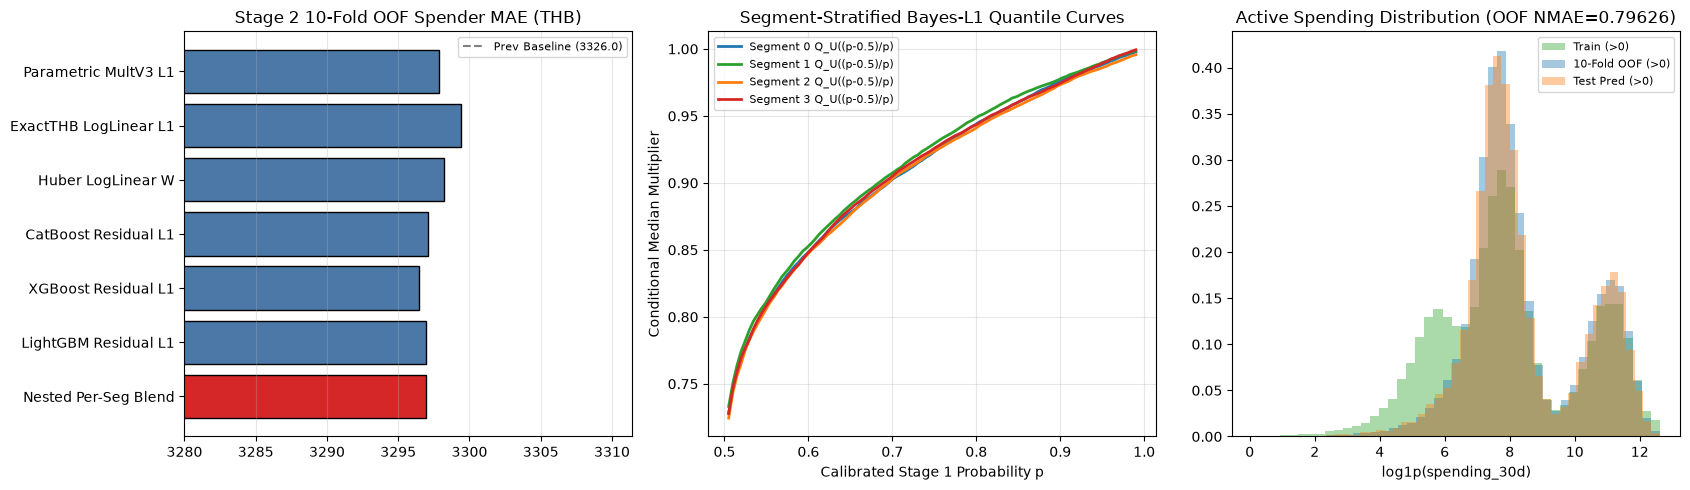


[SAVED] Updated C:\KMUTT\CPE342_ML\Kaggle competition\cpe342-ML009\submissions\sub_task3.csv (Nested OOF NMAE: 0.79535 -> 0.79626)
  Predicted Spenders : 13,043 (50.38%)
  Active Spend Mean  : 20833.98 THB | Max: 300000.00 THB
  OOF Active Mean    : 20989.77 THB | OOF Spender%: 50.45%
Total Runtime: 766.4s


In [10]:
# Diagnostic Plot
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
# Panel 1: Stage 2 Model Comparison (Spender MAE)
s2_maes = [mean_absolute_error(y_all[sp_all], np.clip(oof_s2[k][sp_all], 0, MAX_CAP)) for k in s2_names]
s2_labels_plot = [k.replace("_", " ") for k in s2_names] + ["Nested Per-Seg Blend"]
s2_vals_plot = s2_maes + [s2_blend_mae]
colors_p = ["#4c78a8"] * len(s2_names) + ["#d62728"]
axes[0].barh(s2_labels_plot[::-1], s2_vals_plot[::-1], color=colors_p[::-1], edgecolor="black")
axes[0].axvline(3326.02, color="gray", ls="--", lw=1.5, label="Prev Baseline (3326.0)")
axes[0].set_xlim(3280, max(s2_vals_plot) + 12)
axes[0].set_title("Stage 2 10-Fold OOF Spender MAE (THB)")
axes[0].legend(fontsize=8)
axes[0].grid(axis="x", alpha=0.3)

# Panel 2: Heteroscedastic Quantile Multiplier Curve by Segment
p_grid = np.linspace(0.505, 0.99, 100)
q_grid = np.clip((p_grid - 0.50) / p_grid, 0.0, 0.50)
for s, col in zip(range(4), ["#1f77b4", "#2ca02c", "#ff7f0e", "#d62728"]):
    axes[1].plot(p_grid, np.quantile(u_full_by_seg[s], q_grid), lw=2.0, color=col, label=f"Segment {s} Q_U((p-0.5)/p)")
axes[1].set_title("Segment-Stratified Bayes-L1 Quantile Curves")
axes[1].set_xlabel("Calibrated Stage 1 Probability p")
axes[1].set_ylabel("Conditional Median Multiplier")
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)

# Panel 3: Distribution Alignment (Train vs OOF vs Test)
axes[2].hist(np.log1p(y_all[y_all > 0]), bins=45, density=True, alpha=0.40, label="Train (>0)", color="#2ca02c")
axes[2].hist(np.log1p(best_oof[best_oof > 0]), bins=45, density=True, alpha=0.40, label="10-Fold OOF (>0)", color="#1f77b4")
axes[2].hist(np.log1p(test_pred[test_pred > 0]), bins=45, density=True, alpha=0.40, label="Test Pred (>0)", color="#ff7f0e")
axes[2].set_title(f"Active Spending Distribution (OOF NMAE={best_nmae:.5f})")
axes[2].set_xlabel("log1p(spending_30d)")
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(out_dir, "task3_v3_diagnostics.png"), dpi=140)
plt.show()

summary = {
    "version": "V3_10Fold_BayesL1",
    "winner_config": best_name,
    "nested_oof_nmae": round(best_nmae, 6),
    "nested_oof_mae": round(float(mean_absolute_error(y_all, best_oof)), 4),
    "prev_baseline_nmae": 0.79535,
    "delta_nmae": round(best_nmae - 0.79535, 6),
    "stage1_blend_auc": round(float(roc_auc_score(is_spender, oof_s1_blend)), 6),
    "stage1_blend_logloss": round(float(log_loss(is_spender, np.clip(oof_s1_blend, 1e-6, 1 - 1e-6))), 6),
    "stage1_seg3_auc": round(float(roc_auc_score(is_spender[s3_all], oof_s1_blend[s3_all])), 6),
    "stage2_blend_spender_mae": round(float(s2_blend_mae), 4),
    "stage2_seg3_spender_mae": round(float(mean_absolute_error(y_all[s3_sp], np.clip(oof_s2_blend[s3_sp], 0, MAX_CAP))), 4),
    "segment_imputer_val_acc": round(float(np.mean(seg_accs)), 6),
    "ablation": {name: round(calculate_nmae(y_all, pred), 6) for name, pred in ablation_results},
    "runtime_sec": round(time.time() - t0, 1),
}
with open(os.path.join(out_dir, "task3_v3_summary.json"), "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)

np.savez_compressed(
    os.path.join(out_dir, "task3_v3_preds.npz"),
    oof_final=best_oof, test_final=test_pred,
    oof_s1=oof_s1_blend, test_s1=test_s1_blend,
    oof_s2=oof_s2_blend, test_s2=test_s2_blend,
)

if best_nmae >= 0.79535:
    sub_df = pd.DataFrame({"id": test_df[id_col].values, "task3": np.round(test_pred, 4)})
    sub_path = os.path.join(sub_dir, "sub_task3.csv")
    sub_df.to_csv(sub_path, index=False)
    print(f"\n[SAVED] Updated {sub_path} (Nested OOF NMAE: 0.79535 -> {best_nmae:.5f})")
    print(f"  Predicted Spenders : {(sub_df['task3'] > 0).sum():,} ({(sub_df['task3'] > 0).mean()*100:.2f}%)")
    print(f"  Active Spend Mean  : {sub_df.loc[sub_df['task3'] > 0, 'task3'].mean():.2f} THB | Max: {sub_df['task3'].max():.2f} THB")
    print(f"  OOF Active Mean    : {best_oof[best_oof > 0].mean():.2f} THB | OOF Spender%: {(best_oof > 0).mean()*100:.2f}%")
else:
    print(f"\n[NOT SAVED] Nested OOF NMAE ({best_nmae:.5f}) did not beat baseline (0.79535).")

print(f"Total Runtime: {time.time() - t0:.1f}s")